# Plato Input Catalogue (PIC) 2.2.0.1 

This notebook explores the PIC 2.2.0.1 catalogue and its sub-PICs. Ultimately the goal of this work is to produce feather-format files that can used by `picsim` to generate on-demand stellar catalogues to be used by `platonium`. The output feather-format catalogues from this notebook are placed on the KU Leuven FTP located at `/STER/platoman/ftp`. From that location, `picsim` automatically downloads these files upon first execution and you can enjoy the user-friendly interface of `picsim` to generate your sub-PIC catalogues used by `PlatoSim`.

**Prerequsites** 

To run this notebook you need to download the PIC 2.1.0.1 from the [PAX](https://pax.esac.esa.int/plato/#/pages/catalog-explorer). Unzip the following two files:

- `LOPS2PICtarget2.2.0.1-t-fg-c-scv.fits`
- `LOPS2PICcontaminant2.2.0.1-t-fg-c-scv.fits`

and place them in the location: `$PLATO_PROJECT_HOME/inputfiles/data_picsim`.

**Documentation** 

The following technical notes helps you understand the PIC:

- `LOPS2PIC2.2.0.1 Release Notes (for PIC users)`
- `LOPS2PIC2.2.0.1 Data Definition Document`

**Last checked** 

This notebook was last functional with the PlatoSim version:

- `PlatoSim 3.7.0-191-g42fc64d4`

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib notebook

In [20]:
# Default packages
import os
import sys
import glob

# PlatoSim default
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PLATOnium default
from pathlib import Path
from astropy.io import fits
from astropy.table import Table
from astropy.coordinates import SkyCoord
from astropy import units as u

# PlatoSim libraries
import platosim.plot      as pt
import platosim.utilities as ut
import platosim.pic       as pic
from platosim.matplotlibrc import setup_paper
setup_paper(warning=False)

from IPython.display import display, HTML
display(HTML("<style>.container {width:90% !important; }</style>"))

Relative path to catalogues (if you have placed the catalogue somewhere else on your system, simple alter the following path):

In [3]:
path = ut.getHomeDir('inputfiles/data_picsim')

---
## LOPS2 PIC 2.2.0.1 targets
---

This catalogue is the main target table, composed by the merge of four different target lists:

- `tPIC`: Core science stars (P1, P2, P4, P5) and stars with confirmed/candidate planet(s)
- `fgPIC`: Fine Guidance System (FGS) stars used to guarantee the attitude of the spacecraft
- `cPIC`: Instrument calibration stars
- `scvPIC`: Calibration and validation stars for both stellar and exoplanets science

Load target catalogue into data frame:

In [31]:
filename_targets = path / 'LOPS2PICtarget2.2.0.1-t-fg-c-scv.fits'

We will use the PIC utilities to fetch a few columns:

In [32]:
pic = PIC2201(filename_targets)

For the remaining columns we fetch them manually from a data frame:

In [33]:
table = Table.read(filename_targets, format='fits')
df = table.to_pandas()
df.head()

,PICid,PICname,StarName,RAdeg,eRAdeg,DEdeg,eDEdeg,pmRA,epmRA,pmDE,...,BOLnCameraObsNCAM_T,BOLnCameraSatNCAM_T,EOLrandomNSRNCAM_R,EOLrandomSysNSRNCAM_R,EOLnCameraObsNCAM_R,EOLnCameraSatNCAM_R,tPICscientificRanking,scvPICscientificRanking,scientificPriority,scheduledTarget
0,3098133000271,b'PIC 3098133000271',b'Gaia DR3 4648564604791874688',84.548965,0.159458,-75.874403,0.180793,-3.102064,0.012864,12.663421,...,0,0,133.600006,133.899994,0,0,0.004622,<NA>,<NA>,<NA>
1,3098130000327,b'PIC 3098130000327',b'Gaia DR3 4648246433616908160',82.636521,0.126920,-75.871390,0.139425,20.555716,0.010246,40.802000,...,0,0,152.399994,152.699997,0,0,0.015314,<NA>,<NA>,<NA>
2,3098125000342,b'PIC 3098125000342',b'Gaia DR3 4648987573177352576',79.661507,0.174732,-75.867457,0.157135,-4.791629,0.013962,9.420978,...,0,0,281.799988,282.000000,0,0,0.000974,<NA>,<NA>,<NA>
3,3098136000261,b'PIC 3098136000261',b'Gaia DR3 4648377790895956096',86.259963,0.163587,-75.861752,0.200761,-1.406063,0.013268,22.950370,...,0,0,152.399994,152.699997,0,0,0.000776,<NA>,<NA>,<NA>
4,3098125000383,b'PIC 3098125000383',b'Gaia DR3 4648987465797348480',79.572931,0.187630,-75.858905,0.174225,7.379638,0.014900,-5.899641,...,0,0,279.700012,279.799988,0,0,0.001540,<NA>,<NA>,<NA>


Check the column names:

In [34]:
df.columns

Index(['PICid', 'PICname', 'StarName', 'RAdeg', 'eRAdeg', 'DEdeg', 'eDEdeg',
       'pmRA', 'epmRA', 'pmDE', 'epmDE', 'pm', 'epm', 'Plx', 'ePlx',
       'distance', 'edistance', 'Glon', 'Glat', 'posEpoch', 'refEpoch',
       'posPropFlag', 'PlatoMagNCAM', 'ePlatoMagNCAM', 'PlatoMagFCAMb',
       'ePlatoMagFCAMb', 'PlatoMagFCAMr', 'ePlatoMagFCAMr', 'Gmag', 'eGmag',
       'BPmag', 'eBPmag', 'RPmag', 'eRPmag', 'Hpmag', 'eHpmag', 'Ksmag',
       'eKsmag', 'AG', 'eAG', 'AKs', 'eAKs', 'EBPRP', 'eEBPRP', 'extStatus',
       'VmagCalculated', 'eVmagCalculated', 'Teff', 'eTeff', 'Radius',
       'eRadius', 'Mass', 'eMass', 'caseFlag', 'PICmainSourceFlagBOL',
       'tPICsourceFlagNCAM_BOL', 'fgPICsourceFlag', 'cPICsourceFlag',
       'scvPICsourceFlag', 'NSSFlag', 'qualityFlag', 'tPICplanetFlag',
       'fgPICcPICvariabilityFlag', 'targetStatusFlag', 'BOLrandomNSRNCAM_T',
       'BOLrandomSysNSRNCAM_T', 'BOLnCameraObsNCAM_T', 'BOLnCameraSatNCAM_T',
       'EOLrandomNSRNCAM_R', 'EOLrandomSysNSR

Define a new dataframe and copy over the columns we need:

In [35]:
# Add Galactic coordinates
gal = SkyCoord(df.RAdeg, df.DEdeg, frame='icrs', unit=u.deg).galactic
# Create data frame
dt = pd.DataFrame()
dt['PIC']     = df.PICid
dt['gaiaDR3'] = df.StarName #pic.get_GDR3idnumber()
dt['l']       = gal.l.deg
dt['b']       = gal.b.deg
dt['ra']      = df.RAdeg
dt['dec']     = df.DEdeg
dt['pmra']    = df.pmRA
dt['pmdec']   = df.pmDE
dt['Pmag']    = df.PlatoMagNCAM
dt['PBmag']   = df.PlatoMagFCAMb
dt['PRmag']   = df.PlatoMagFCAMr
dt['M']       = df.Mass
dt['R']       = df.Radius
dt['Teff']    = df.Teff
dt['logg']    = pic.get_logg()
dt['ncams']   = df.BOLnCameraObsNCAM_T
dt['case']    = df.caseFlag
dt['source']  = df.PICmainSourceFlagBOL
dt['tPIC']    = df.tPICsourceFlagNCAM_BOL
dt['fgPIC']   = df.fgPICsourceFlag
dt['cPIC']    = df.cPICsourceFlag
dt['scvPIC']  = df.scvPICsourceFlag
dt.ncams.unique()

<IntegerArray>
[0, 6, 12, 18, 24, <NA>]
Length: 6, dtype: Int16

Remove stars ouside of visibility flower and save `picsim` target catalogue:

In [36]:
dt0 = dt[dt.ncams != 0]
dt0 = dt0.reset_index(drop=True)
dt0.to_feather(path / 'PIC220_LOPS2_targets.ftr')
dt0

,PIC,gaiaDR3,l,b,ra,dec,pmra,pmdec,Pmag,PBmag,...,R,Teff,logg,ncams,case,source,tPIC,fgPIC,cPIC,scvPIC
0,3080732000391,b'Gaia DR3 4651104712875066752',284.772881,-31.906852,81.665938,-73.515292,-3.728212,-0.457188,12.457698,12.685214,...,1.555184,5875.683537,4.139318,6,1,4,4,0,0,0
1,3081447001197,b'Gaia DR3 4649660886611651840',284.937929,-32.507817,79.491661,-73.513287,4.217414,16.632071,12.384645,12.640297,...,2.082860,5647.124223,3.914624,6,1,4,4,0,0,0
2,3080725000536,b'Gaia DR3 4649672843800722176',285.023058,-32.840137,78.295726,-73.496782,-8.735302,17.504225,12.413620,12.679588,...,0.883459,5528.854620,4.513439,6,1,4,4,0,0,0
3,3080736000695,b'Gaia DR3 4650366188962452224',284.603223,-31.373280,83.607288,-73.477299,-9.698397,30.444164,11.902795,12.126169,...,0.987236,5867.405761,4.460903,6,1,4,4,0,0,0
4,3080737000627,b'Gaia DR3 4650412501590382976',284.567042,-31.197444,84.235055,-73.477136,-8.475994,50.955199,10.948108,11.182121,...,1.216444,5739.879064,4.303131,6,1,4,4,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
218141,2584245001092,b'Gaia DR3 5534611474577640576',256.287032,-4.172328,121.700934,-39.982180,-0.605033,7.863984,12.467970,13.172366,...,9.171690,5273.540000,2.911935,12,4,32,0,0,0,8192
218142,2375324001251,b'Gaia DR3 5598585532155150208',246.441913,-2.342952,117.339771,-30.635653,-5.730499,9.028191,12.495300,13.086321,...,10.752600,5487.600000,2.823342,6,4,32,0,0,0,8192
218143,2947056000215,b'Gaia DR3 5289461200952847616',273.252793,-17.231338,116.497274,-60.880089,-0.596529,3.962600,12.516080,13.036754,...,NaN,NaN,NaN,6,4,32,0,0,0,8192
218144,2639419000234,b'Gaia DR3 5526512922907328896',261.173625,-1.907725,127.855655,-42.742764,-2.010023,2.125126,12.499554,13.074980,...,8.882790,4805.250000,2.990470,6,4,32,0,0,0,8192


---
## LOPS2 PIC 2.2.0.1 contaminants
---

Open fits file and inspect it:

In [11]:
filename = path / 'LOPS2PICcontaminant2.2.0.1-t-fg-c-scv.fits'
hdul = fits.open(filename, memmap=True)

Note that this catalogue contains 105,865,176 sources:

In [12]:
hdul.info()

Filename: /lhome/nicholas/software/PlatoSim3/inputfiles/data_picsim/LOPS2PICcontaminant2.2.0.1-t-fg-c-scv.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1                1 BinTableHDU    217   105865176R x 43C   [K, 17A, 28A, D, D, D, D, D, E, D, E, D, D, D, E, E, E, E, E, I, D, D, D, D, D, D, I, D, D, D, D, D, D, E, E, E, E, E, E, I, I, I, I]   


Check tabel column names

In [13]:
hdul[1].header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / 8-bit bytes                                    
NAXIS   =                    2 / 2-dimensional table                            
NAXIS1  =                  285 / width of table in bytes                        
NAXIS2  =            105865176 / number of rows in table                        
PCOUNT  =                    0 / size of special data area                      
GCOUNT  =                    1 / one data group                                 
TFIELDS =                   43 / number of columns                              
TTYPE1  = 'PICcontaminantId'   / label for column 1                             
TFORM1  = 'K       '           / format for column 1                            
TCOMM1  = 'Unique PIC contaminant identifier'                                   
TUCD1   = 'meta.id;meta.main'                                                   
TTYPE2  = 'PICcontaminantNam

Workaround to load huge data table into a data frame:

In [14]:
dc = pd.DataFrame()
campos = {
    'PIC'     : 'PICcontaminantId',
    'gaiaDR3' : 'StarName',
    'ra'      : 'RAdeg', 
    'dec'     : 'DEdeg',
    'Gmag'    : 'Gmag',
    'Pmag'    : 'PlatoMagNCAM',
    'PBmag'   : 'PlatoMagFCAMb',
    'PRmag'   : 'PlatoMagFCAMr'
}
print('FECTHING COLUMNS FROM CONTAMINANT TABLE:')
print('-'*40)
for campo_dc, campo_pic in campos.items():
    # Print each column to follow progress
    print(campo_pic)
    col = hdul[1].data[campo_pic]
    # Fetch magnitude column and get bool indices for P < 19
    if campo_dc == 'Pmag':
        dx = pd.DataFrame({'Pmag': col})
        dex = dx.Pmag < 19
    # Fetch each column
    dc[campo_dc] = col.byteswap().view(col.dtype.newbyteorder())
print('-'*40)

FECTHING COLUMNS FROM CONTAMINANT TABLE:
----------------------------------------
PICcontaminantId
StarName
RAdeg
DEdeg
Gmag
PlatoMagNCAM
PlatoMagFCAMb
PlatoMagFCAMr
----------------------------------------


In [24]:
dc['gaiaDR3'] = pic.get_GaiaDR3_ID(dc, column='gaiaDR3')
dc.head()

,PIC,gaiaDR3,ra,dec,Gmag,Pmag,PBmag,PRmag
0,3110756000112,5212190448627272832,95.193683,-77.886883,15.213778,14.926610,15.235669,14.596222
1,3110756000113,5212190616130246656,95.141286,-77.886858,18.240141,17.982211,18.237360,17.696458
2,3110756000114,5212190482985986944,95.298362,-77.886773,20.510187,20.196406,20.565547,19.821192
3,3110757000129,5212236623819501440,95.888141,-77.886079,20.385687,20.068541,20.446212,19.687329
4,3110757000130,5212236795618194176,95.809169,-77.885670,19.580097,19.334407,19.569914,19.066083


Show the number of sources for different magnitude limits:

In [25]:
dc19 = dc.loc[dex].reset_index(drop=True)
dc19.shape[0]/1e6

45.116663

In [26]:
dc17 = dc[dc.Pmag < 17].reset_index(drop=True)
dc17.shape[0]/1e6

13.125668

In [27]:
dc15 = dc17[dc17.Pmag < 15].reset_index(drop=True)
dc15.shape[0]/1e6

3.385929

In [30]:
path

PosixPath('/lhome/nicholas/software/PlatoSim3/inputfiles/data_picsim')

Save contaminant catalogue to cross-match with for GO proposals

In [91]:
dc19.to_feather(path / 'PlatoGO_PIC220_LOPS2.ftr')

We make a cut to keep the catalogue managable and remove NaNs:

In [28]:
dc17 = dc17.dropna(subset=['PIC', 'ra', 'dec', 'Pmag', 'PBmag', 'PRmag'])
# dc17.pmra = dc17.pmra.replace(np.nan, 0)
# dc17.pmdec = dc17.pmdec.replace(np.nan, 0)

Since the PIC 2.2.0.1 contaminant table do not include unique PIC identifiers related to each target star we need to generate this ourselves:

In [100]:
dc_cut = ut.getContaminants(dt, dc17, column='PIC', radius=60)

100%|██████████████████████████████████████████████████| 289253/289253 [5:33:59<00:00, 14.43it/s]    


In [101]:
dc_cut = dc_cut.reset_index(drop=True)
dc_cut

,PIC,gaiaDR3,ra,dec,Gmag,Pmag,PBmag,PRmag,dis
0,3.098133e+12,Gaia DR3 4648564604797660288,84.561690,-75.885606,12.983585,12.720928,12.983360,12.428690,41.848512
1,3.098136e+12,Gaia DR3 4648377790895955456,86.248821,-75.862302,15.534974,15.256943,15.547705,14.941191,9.995941
2,3.098125e+12,Gaia DR3 4648987470098135424,79.566889,-75.860163,16.274323,15.987543,16.295728,15.657919,6.980812
3,3.098125e+12,Gaia DR3 4648987848055256576,79.559094,-75.845687,17.009531,16.637445,17.164195,16.167209,49.118412
4,3.097516e+12,Gaia DR3 4648381329948992384,85.845627,-75.858153,13.934879,13.483351,14.786755,12.737154,1.003920
...,...,...,...,...,...,...,...,...,...
1403411,2.935596e+12,Gaia DR3 5302121806772404480,129.894228,-60.008217,16.864481,16.572015,16.892075,16.233054,36.894540
1403412,2.935596e+12,Gaia DR3 5302122042991148160,129.895012,-59.992659,15.299934,15.055106,15.289189,14.788033,42.666597
1403413,2.935596e+12,Gaia DR3 5302122047290574848,129.894765,-59.992582,17.298901,16.847372,18.150776,16.101175,43.164681
1403414,2.935596e+12,Gaia DR3 5302497152555006464,129.917282,-59.987334,11.314436,10.953342,11.439109,10.505485,53.531699


Save `picsim` contaminant catalogue:

In [102]:
dc_cut.to_feather(path / 'PIC220_LOPS2_contaminants.ftr')

---
## Plot the PIC target catalogue
---

All PIC targets:

<IPython.core.display.Javascript object>


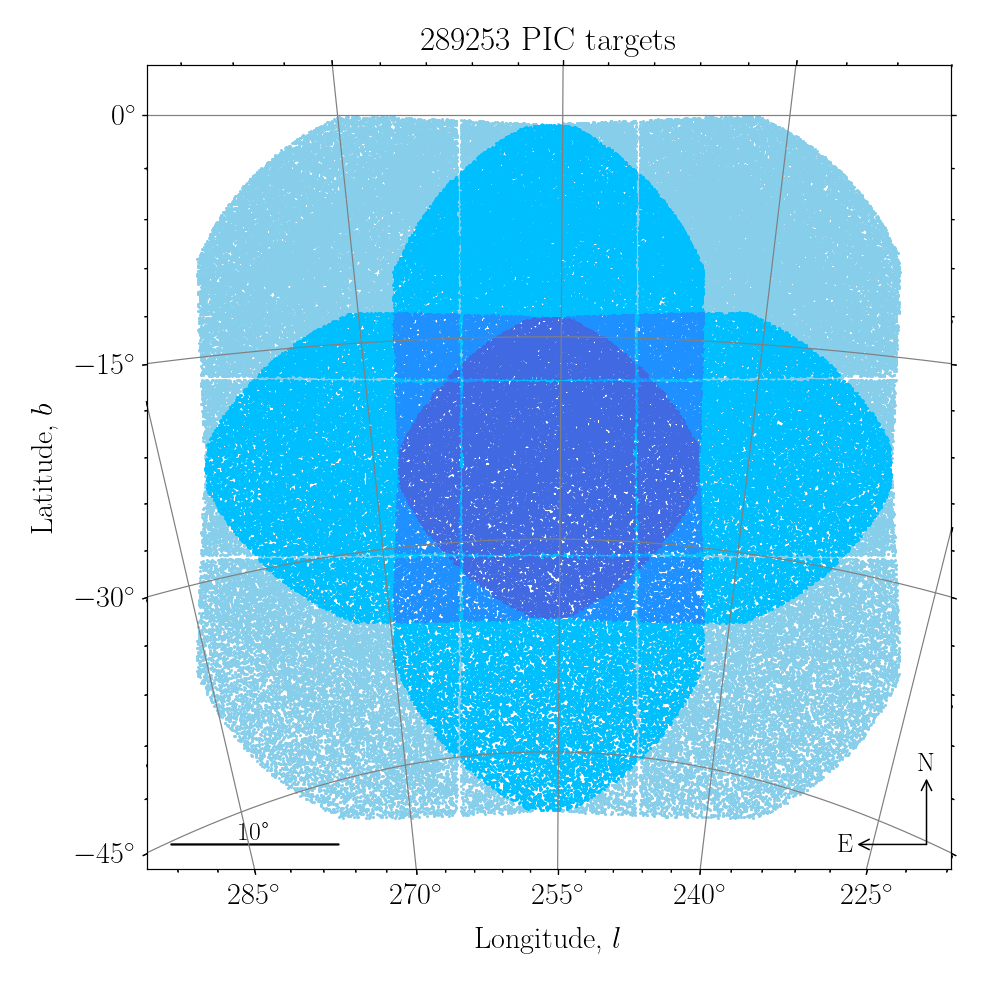

In [28]:
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Settings
    figsize=(9,9), title=f'{dt.shape[0]} PIC targets'
)

---
### Plots for tPIC

Plot `tPIC` targets:

<IPython.core.display.Javascript object>


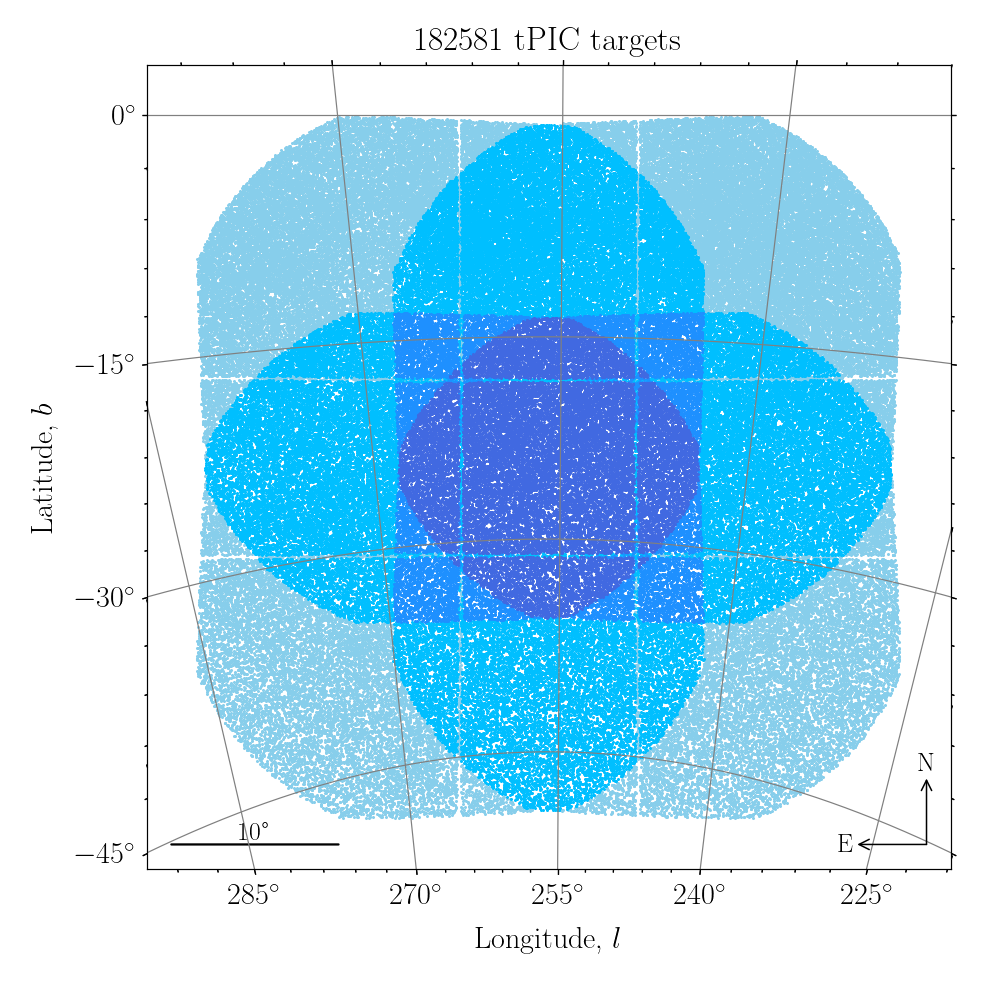

In [29]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['source'] & 4 == 4]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dx,
    # Settings
    figsize=(9,9), title=f'{dx.shape[0]} tPIC targets'
)

Plot all `P1` targets and their planets (candidates):

<IPython.core.display.Javascript object>


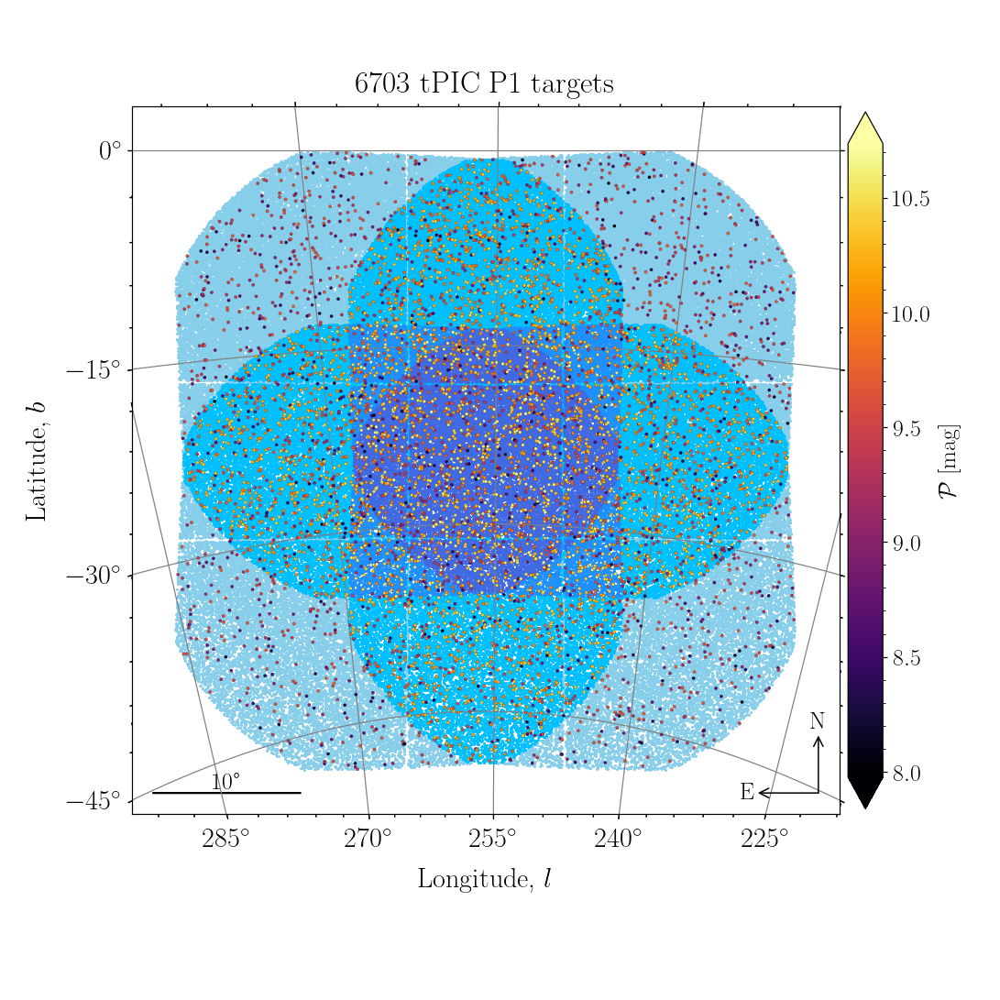

In [30]:
dx = dt[(dt.tPIC == 1) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=20, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P1 targets'
)

<IPython.core.display.Javascript object>


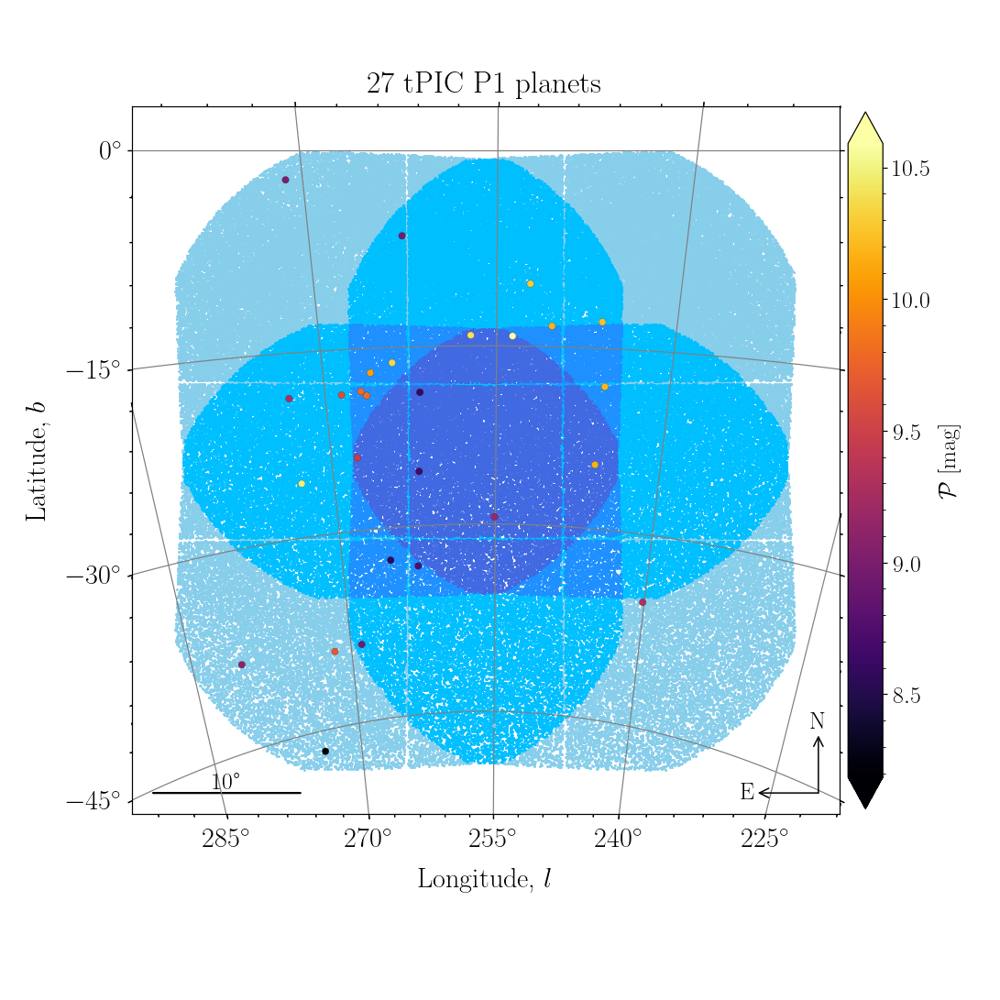

In [31]:
dx = dt[(dt.tPIC == 17) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P1 planets'
)

Plot all `P2` targets and their planets (candidates):

<IPython.core.display.Javascript object>


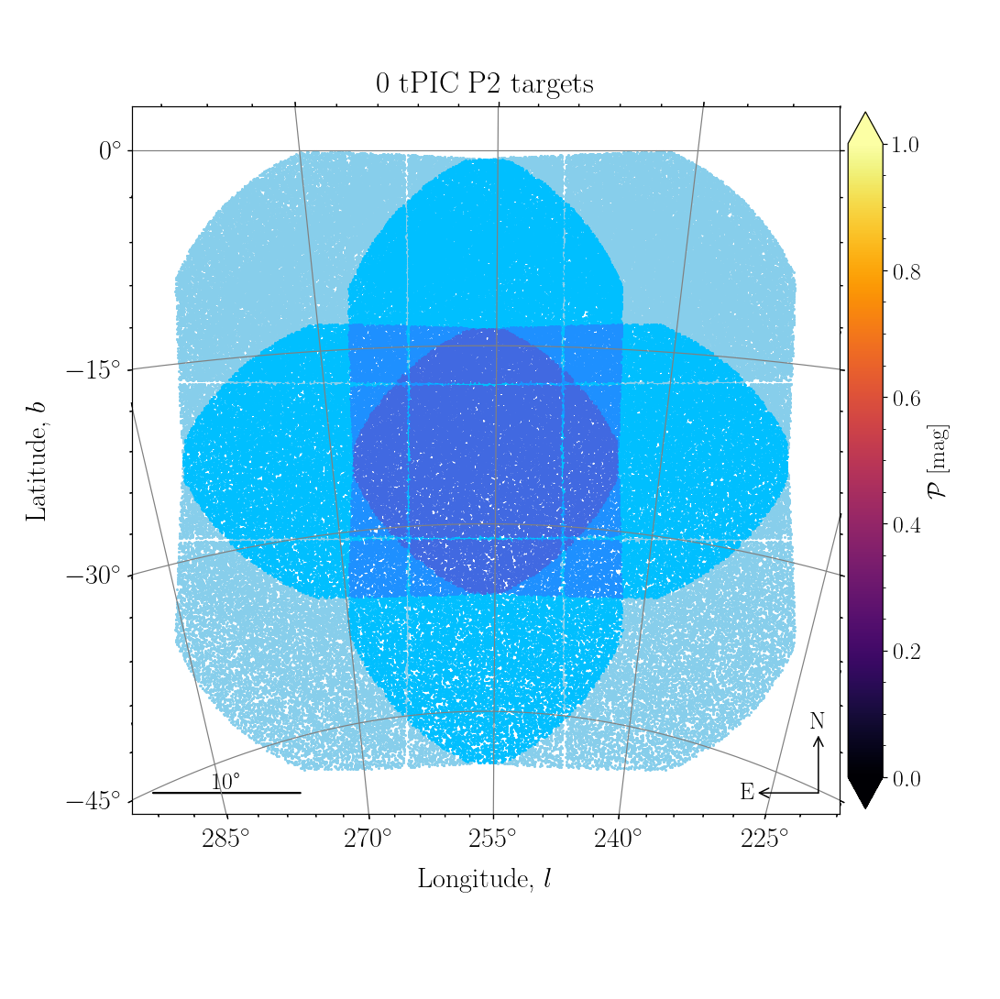

In [32]:
dx = dt[(dt.tPIC == 3) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P2 targets'
)

<IPython.core.display.Javascript object>


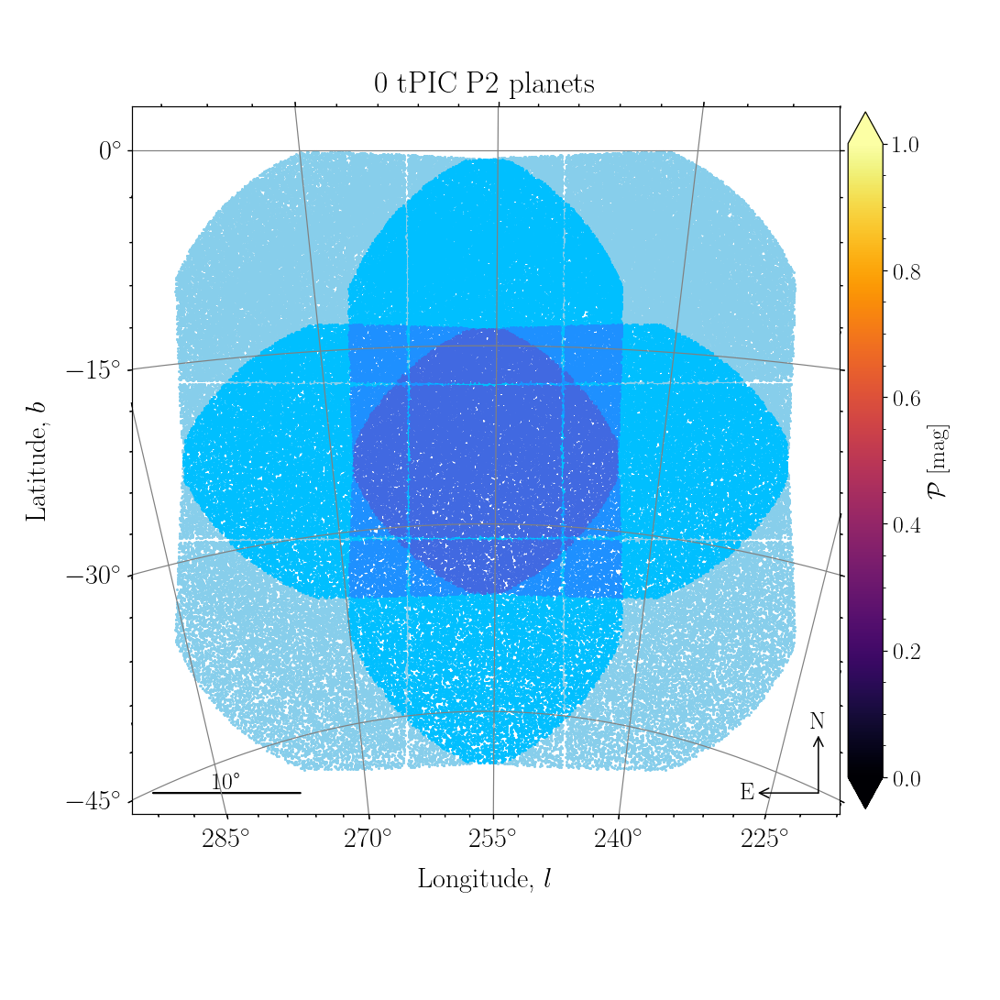

In [33]:
dx = dt[(dt.tPIC == 19) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P2 planets'
)

Plot all `P4` targets and their planets (candidates):

<IPython.core.display.Javascript object>


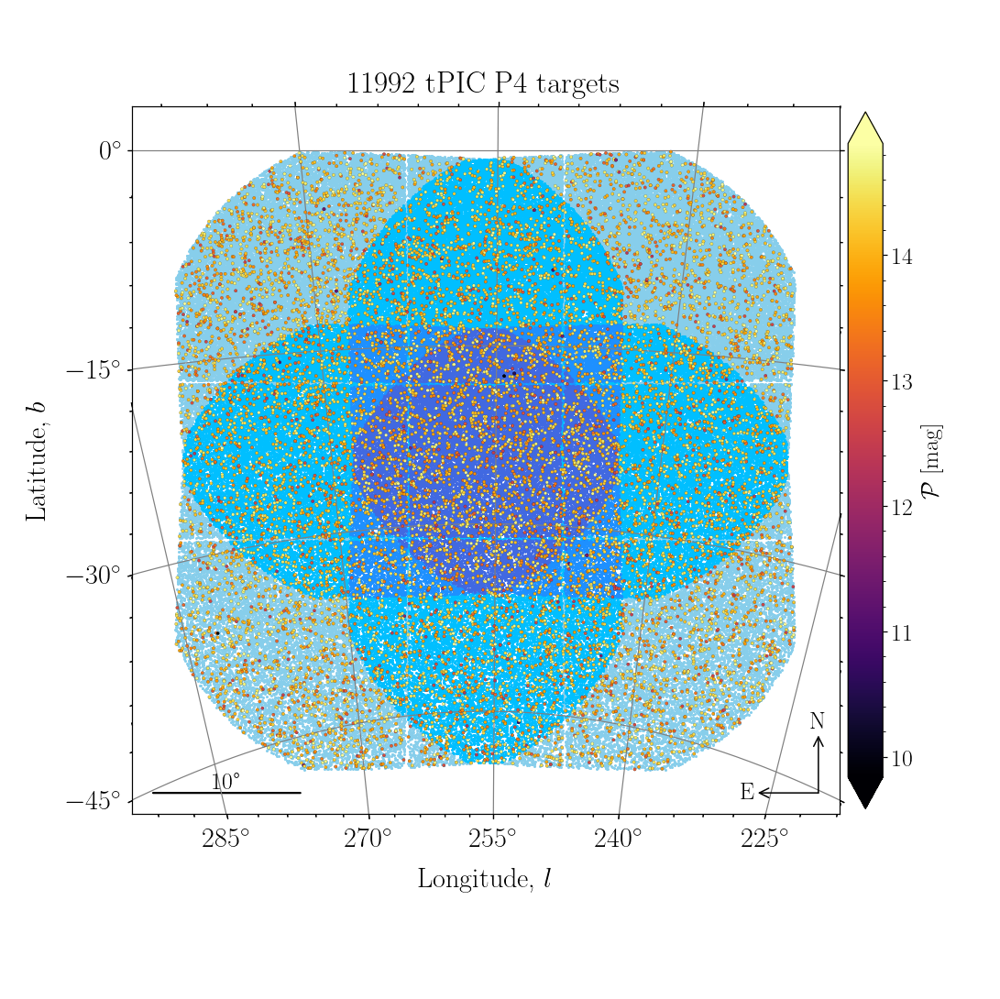

In [34]:
dx = dt[(dt.tPIC == 8) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=20, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P4 targets'
)

<IPython.core.display.Javascript object>


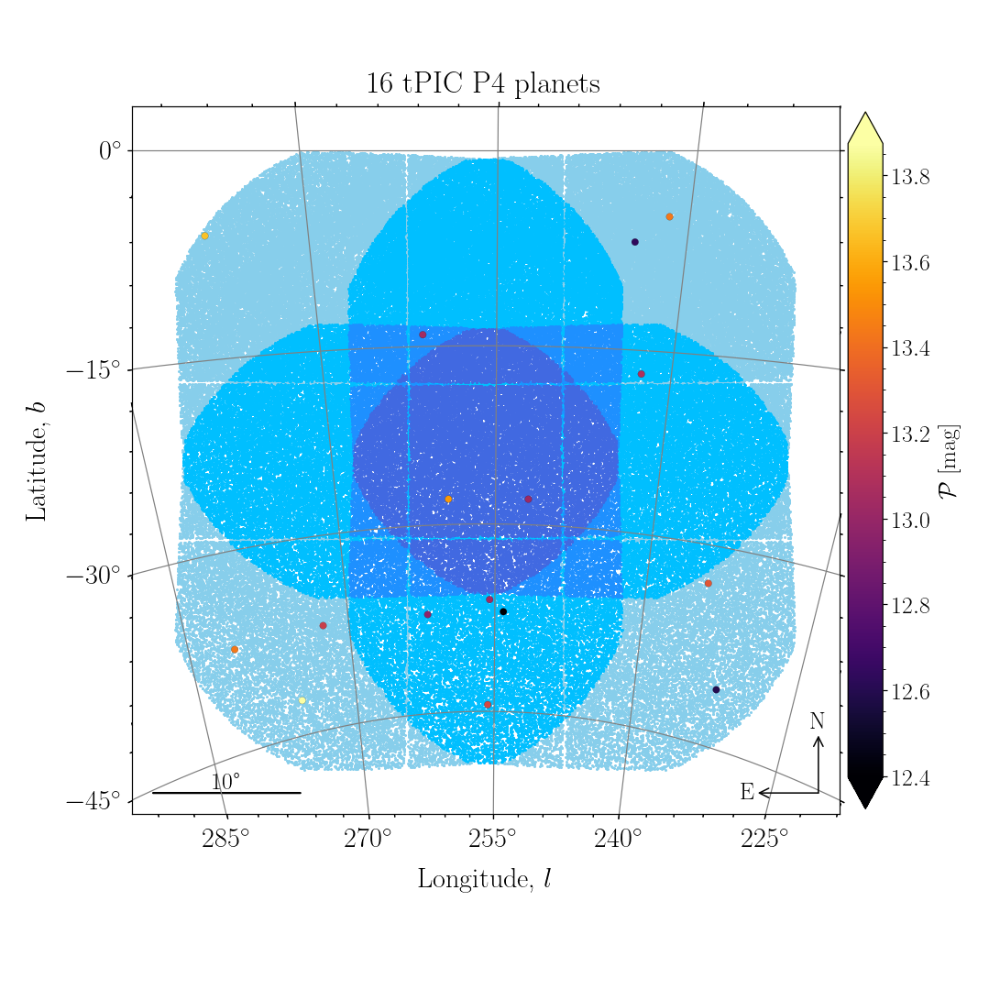

In [35]:
dx = dt[(dt.tPIC == 24) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P4 planets'
)

Plot all `P5` targets and their planets (candidates):

<IPython.core.display.Javascript object>


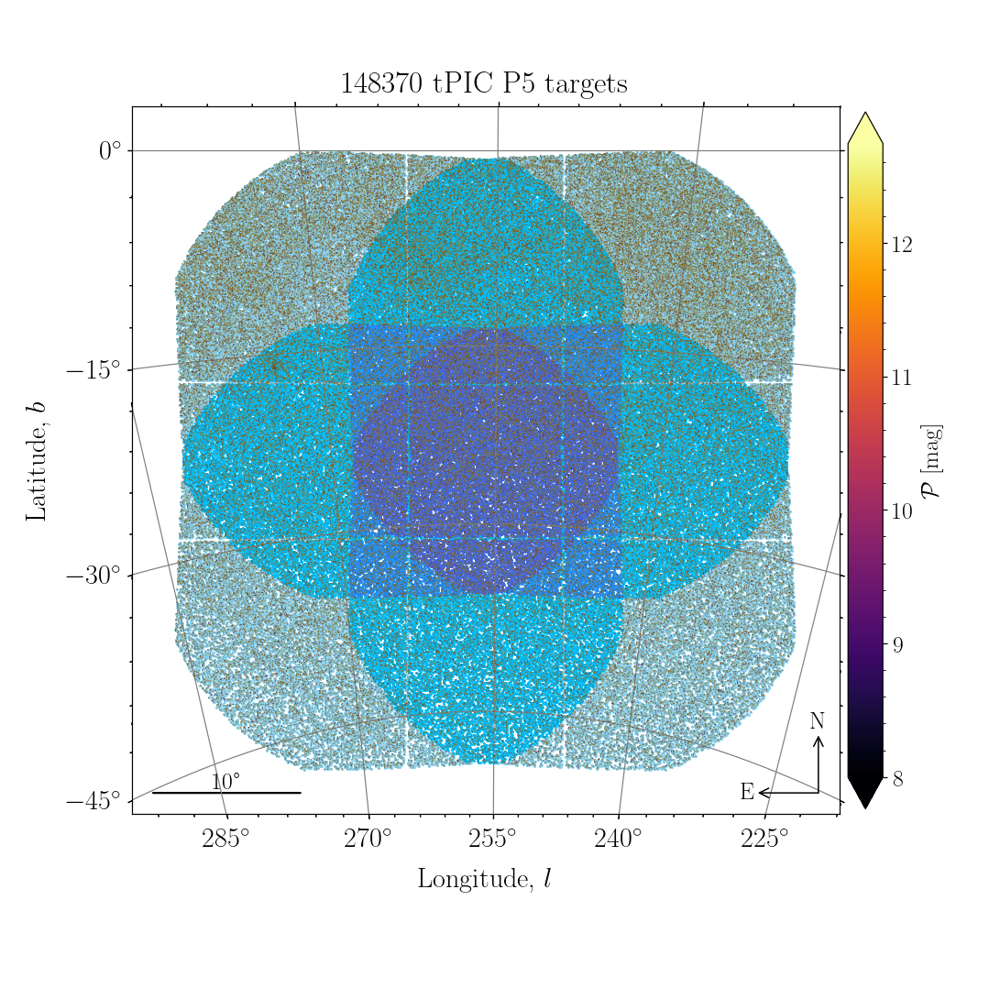

In [36]:
dx = dt[(dt.tPIC == 4) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=1.5, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P5 targets'
)

<IPython.core.display.Javascript object>


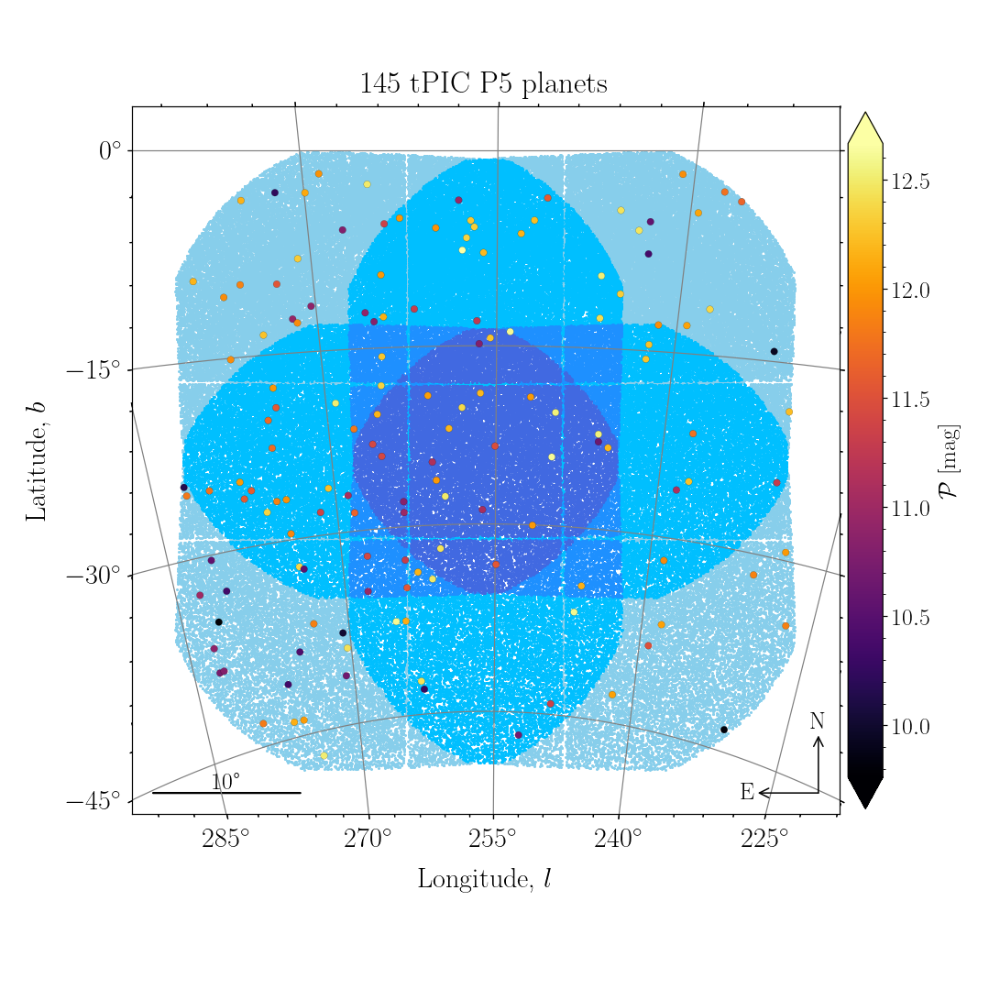

In [37]:
dx = dt[(dt.tPIC == 20) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P5 planets'
)

---
### Plots for fgPIC

Plot `fgPIC` targets:

<IPython.core.display.Javascript object>


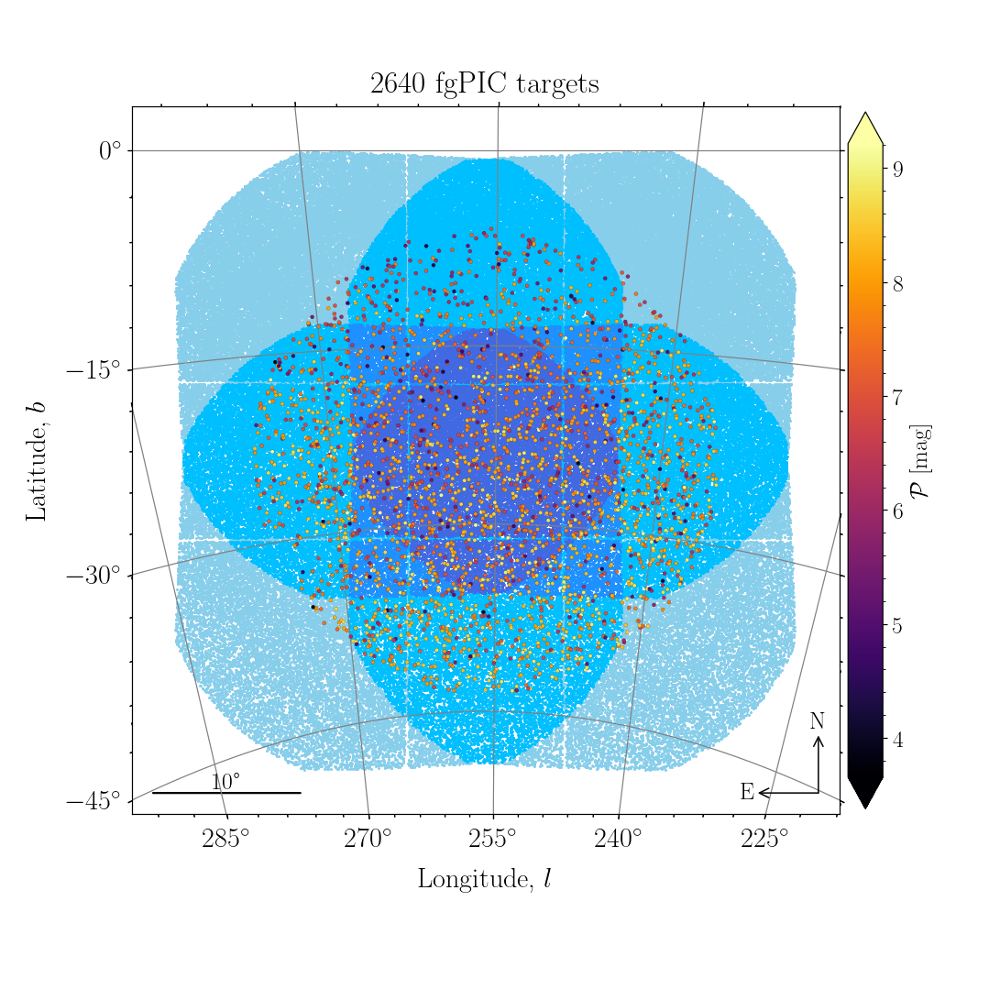

In [38]:
dx = dt.loc[dt.source & 8 == 8]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} fgPIC targets'
)

Plot fgPIC `F-CAMb` targets:

<IPython.core.display.Javascript object>


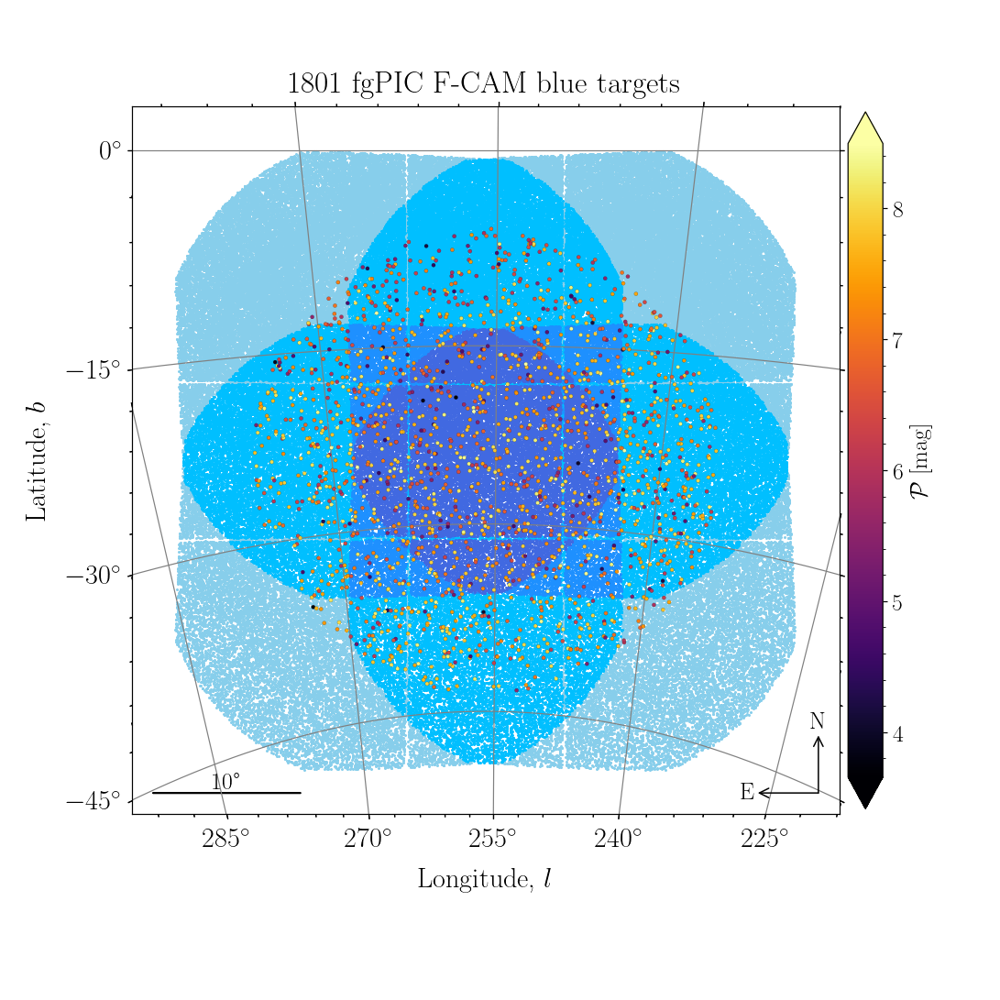

In [39]:
dx = dt.loc[dt.fgPIC & 1 == 1]

fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} fgPIC F-CAM blue targets'
)

Plot fgPIC `F-CAMr` targets:

<IPython.core.display.Javascript object>


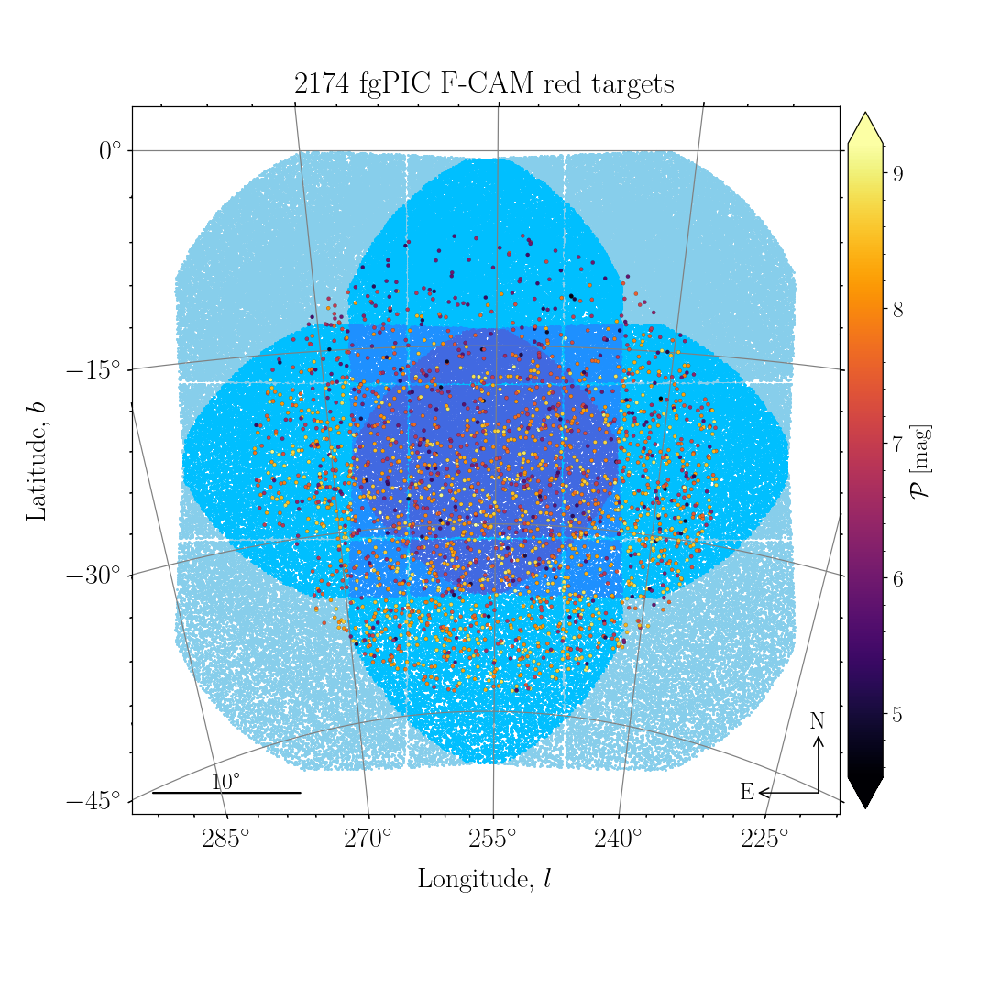

In [40]:
dx = dt.loc[dt.fgPIC & 2 == 2]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} fgPIC F-CAM red targets'
)

---
### Plots for cPIC

Plot `cPIC` targets:

<IPython.core.display.Javascript object>


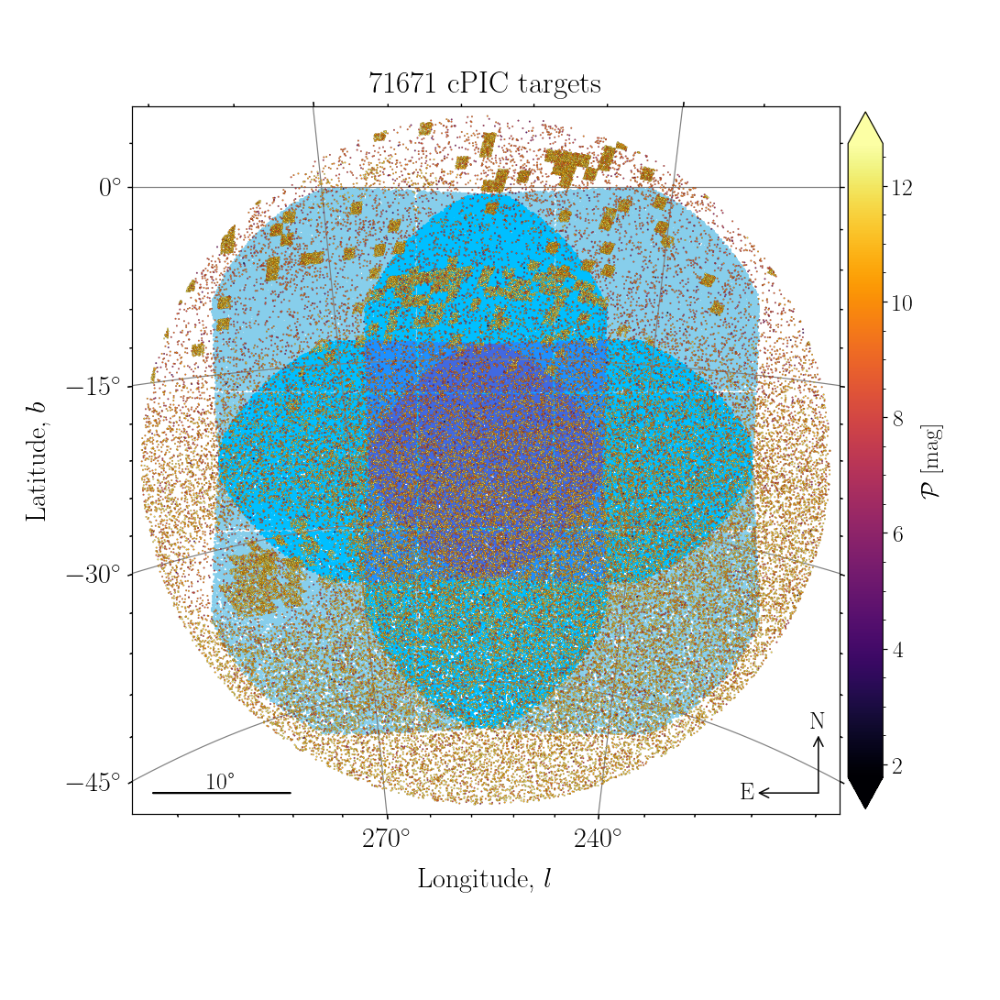

In [41]:
dx = dt
# dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['source'] & 16 == 16]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=34, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=5, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC targets'
)

Plot cPIC `F-CAM R1` sample:

<IPython.core.display.Javascript object>


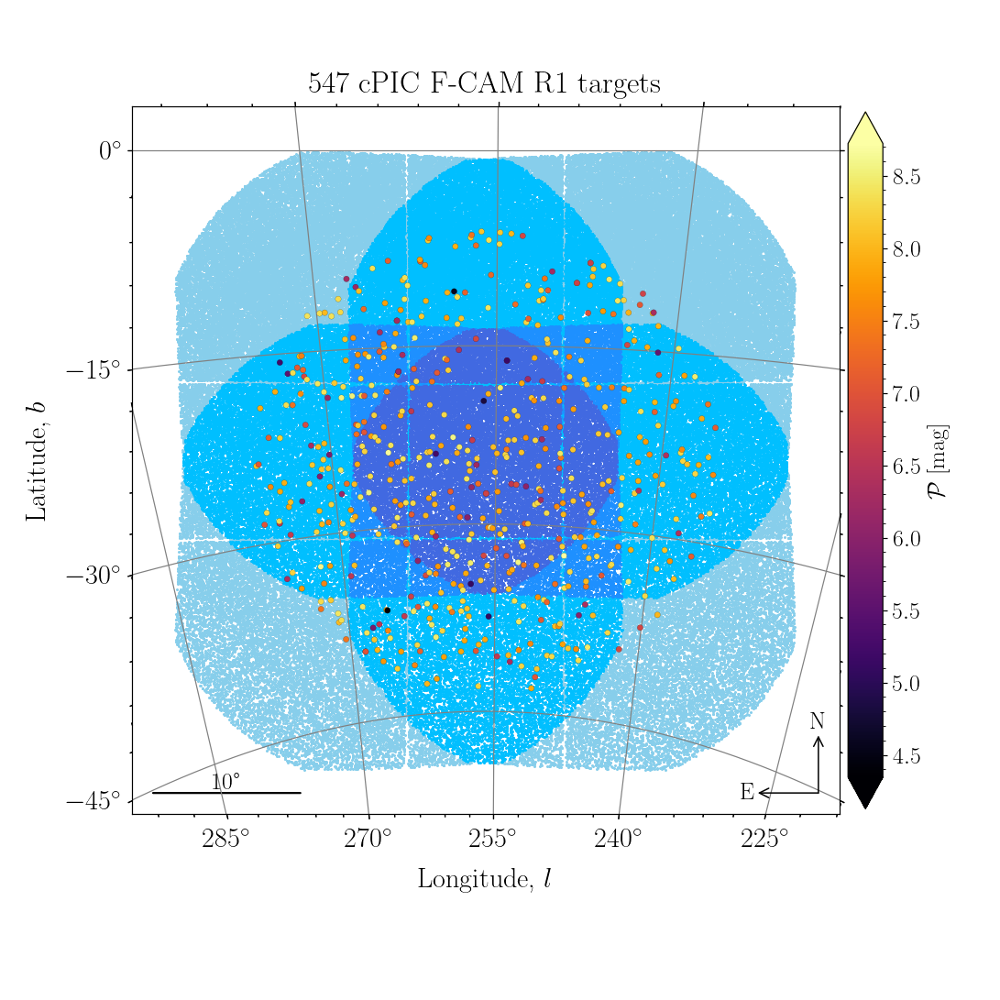

In [42]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 1 == 1]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R1 targets'
)

Plot cPIC `F-CAM R2` sample:

<IPython.core.display.Javascript object>


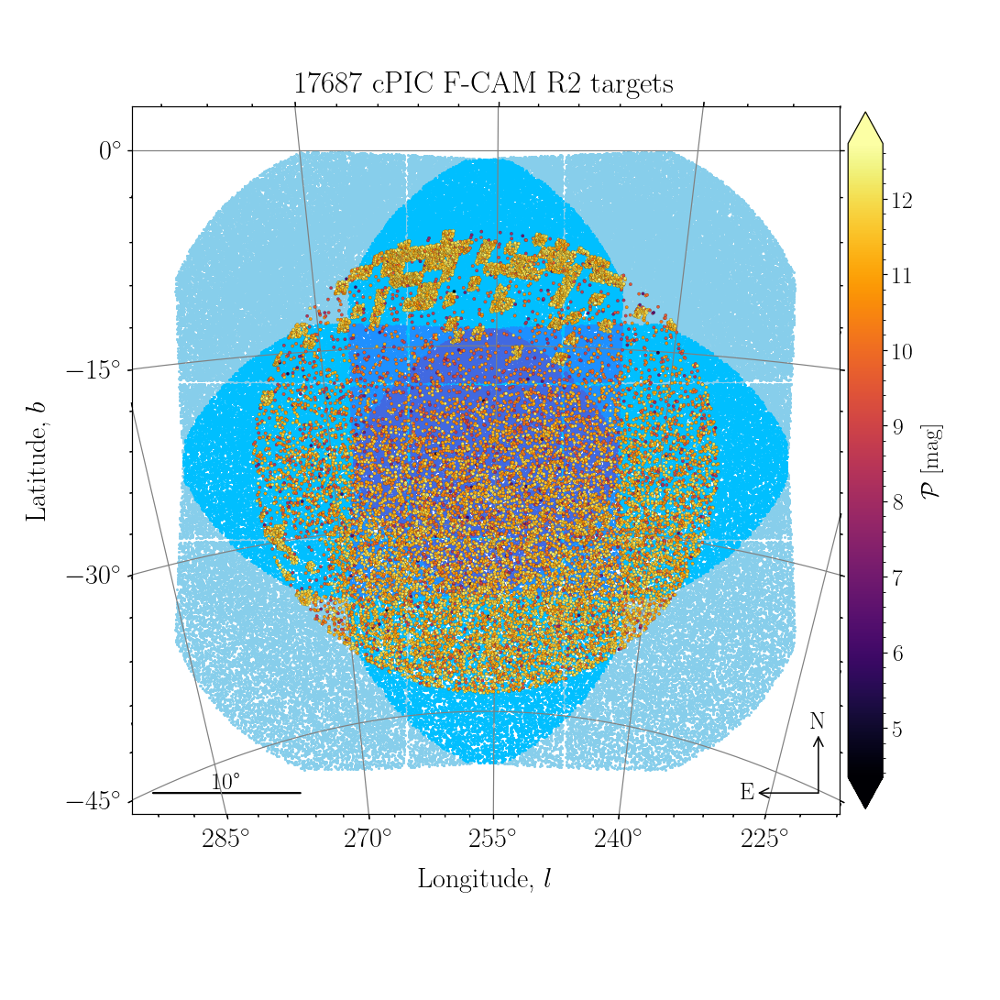

In [43]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 2 == 2]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=20, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R2 targets'
)

Plot cPIC `F-CAM R3` sample:

<IPython.core.display.Javascript object>


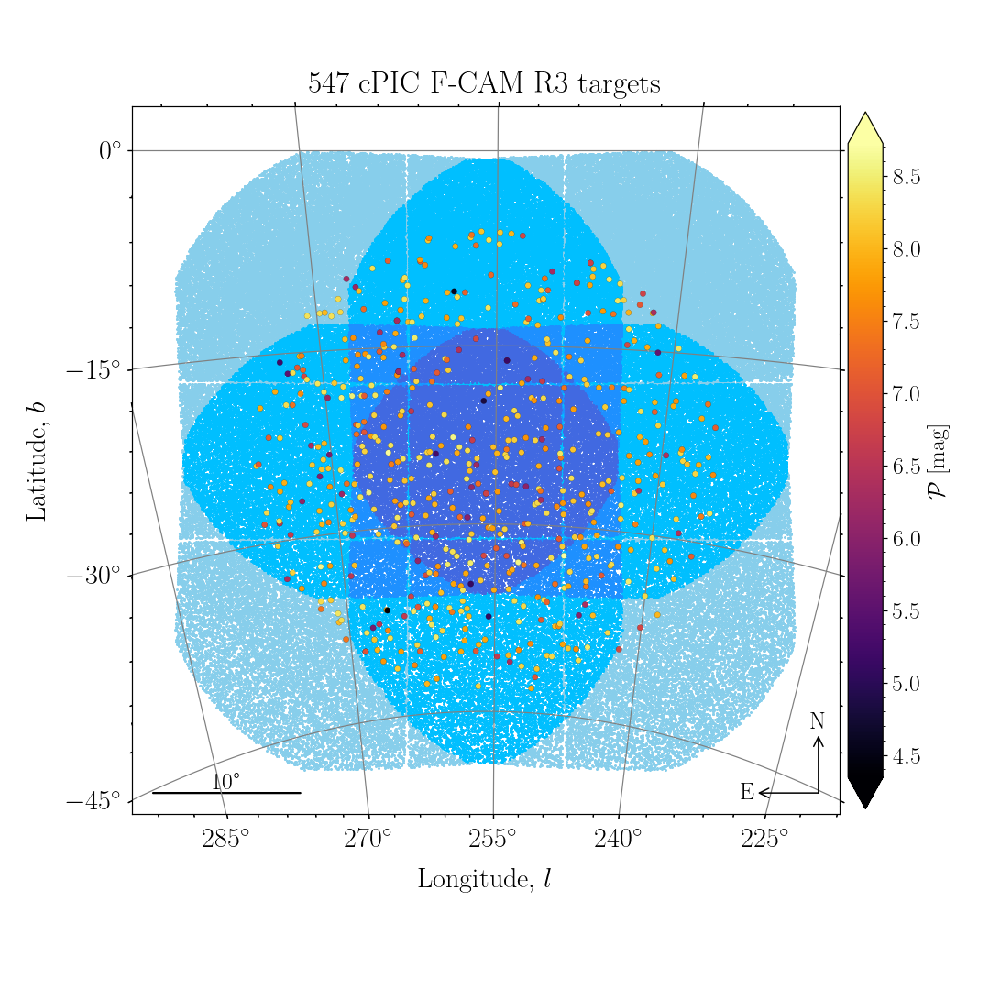

In [44]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 4 == 4]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R3 targets'
)

Plot `cPIC F-CAM R4` sample:

<IPython.core.display.Javascript object>


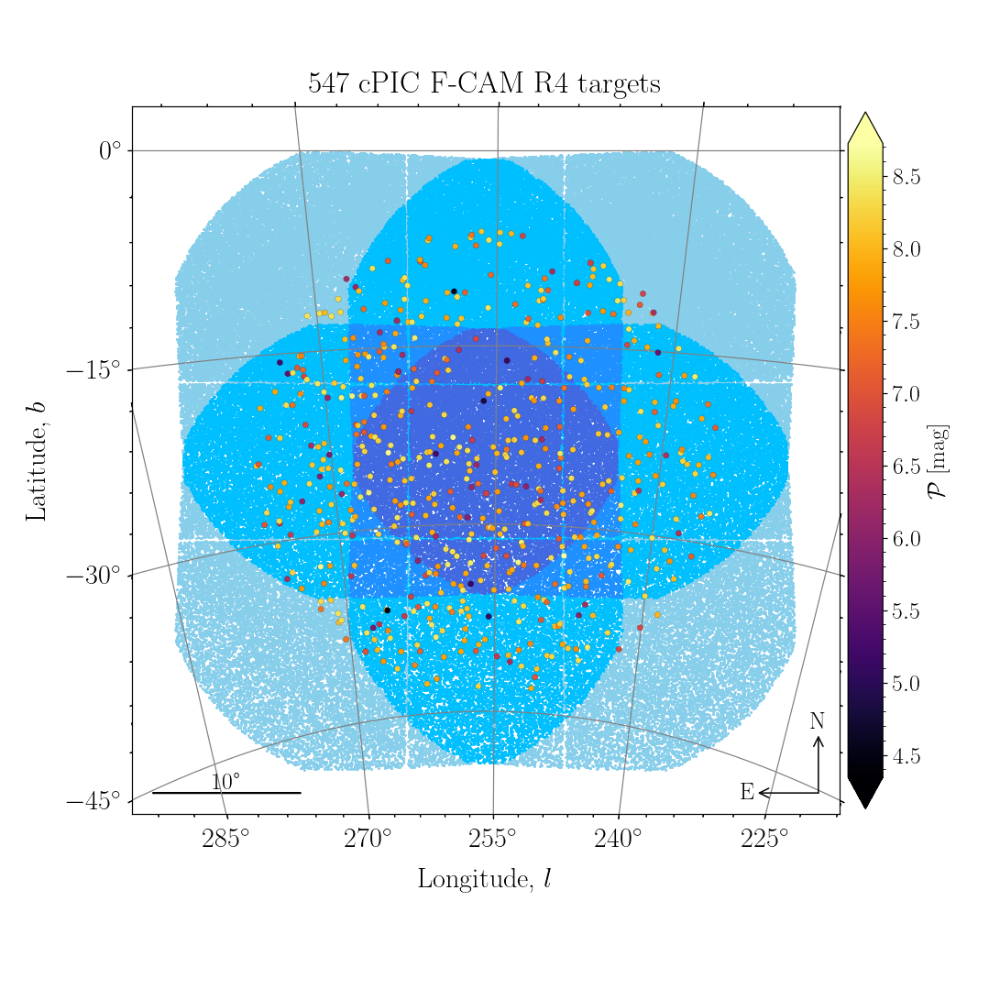

In [45]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 8 == 8]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R4 targets'
)

Plot cPIC `F-CAM R5` sample:

<IPython.core.display.Javascript object>


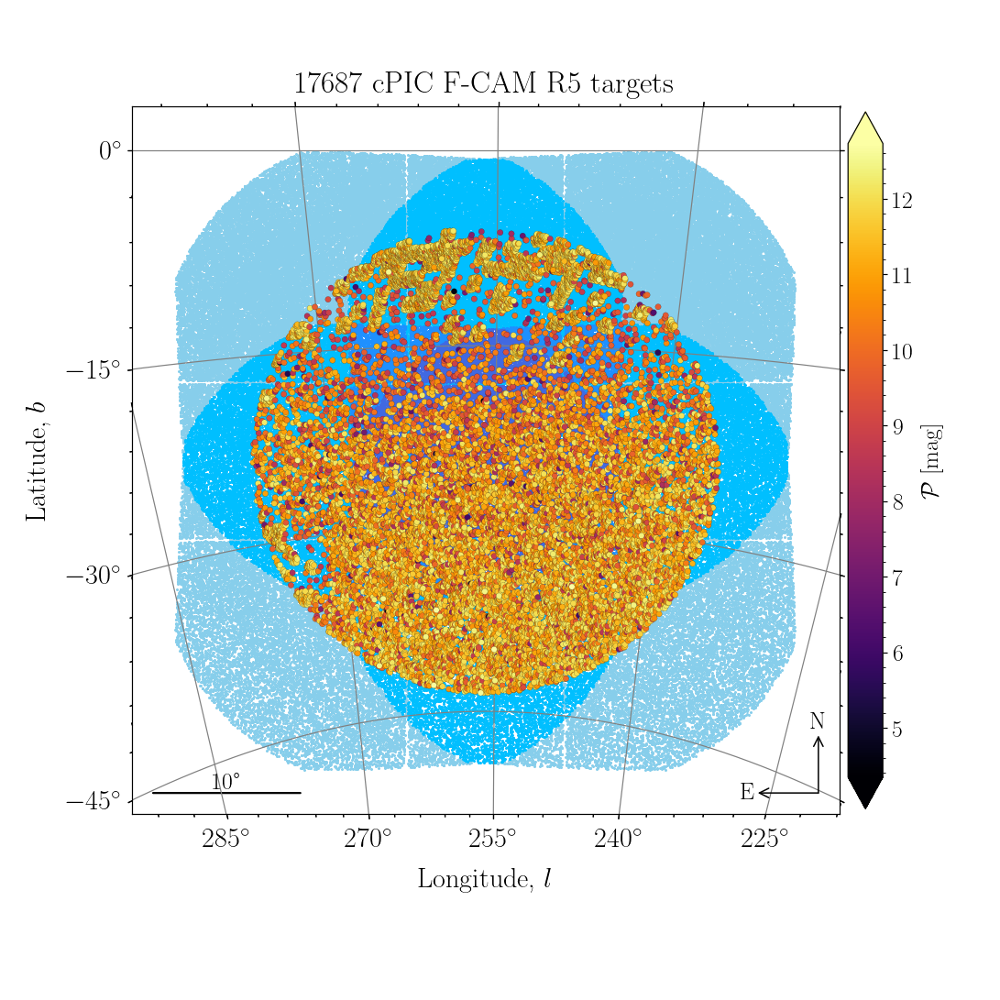

In [46]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 16 == 16]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R5 targets'
)

Plot cPIC `N-CAM R1` sample:

<IPython.core.display.Javascript object>


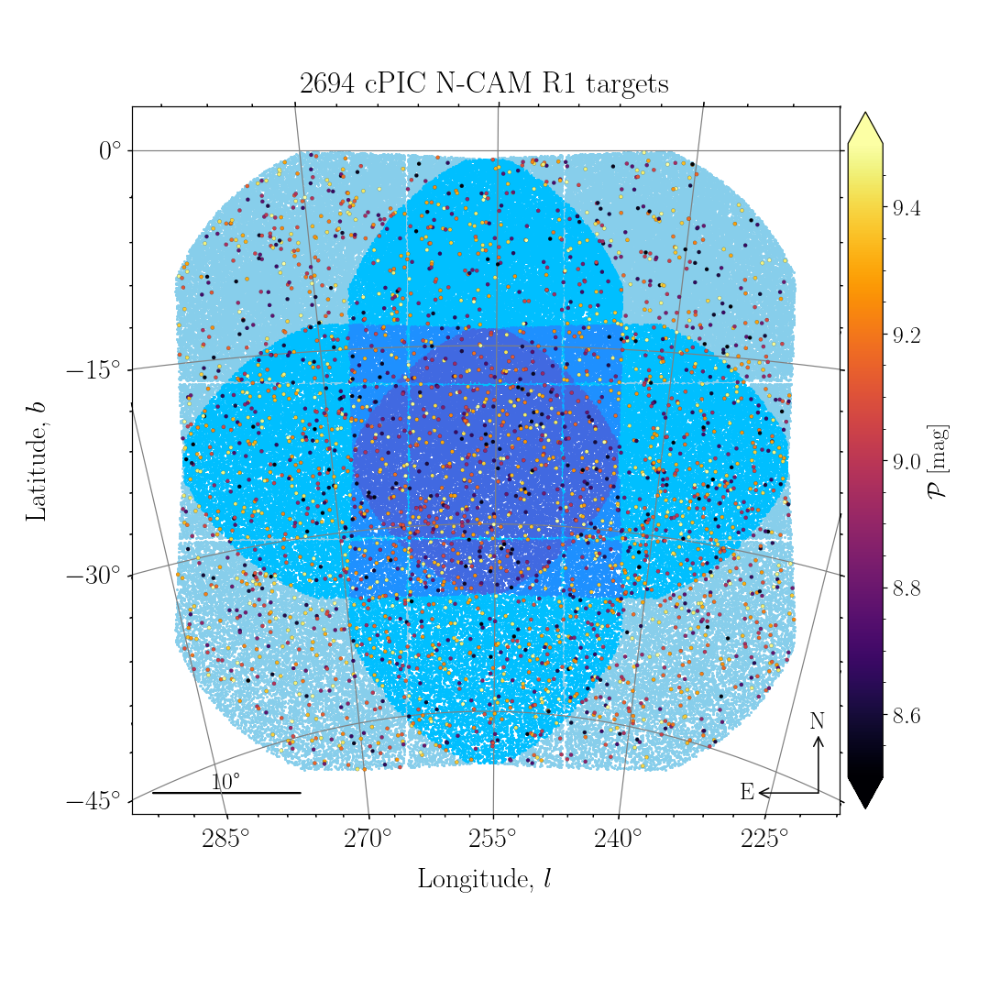

In [47]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 32 == 32]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R1 targets'
)

Plot cPIC `N-CAM R2` sample:

<IPython.core.display.Javascript object>


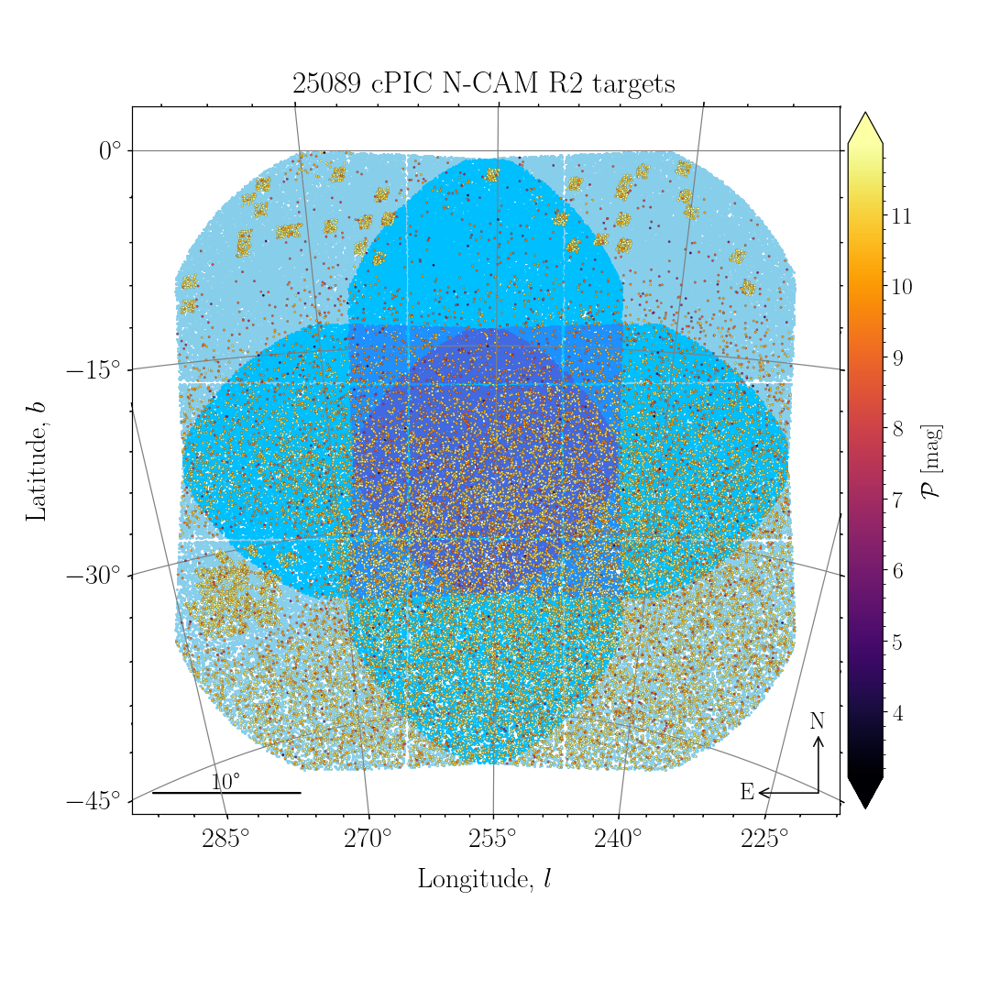

In [48]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 64 == 64]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=10, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R2 targets'
)

Plot cPIC `N-CAM R3` sample:

<IPython.core.display.Javascript object>


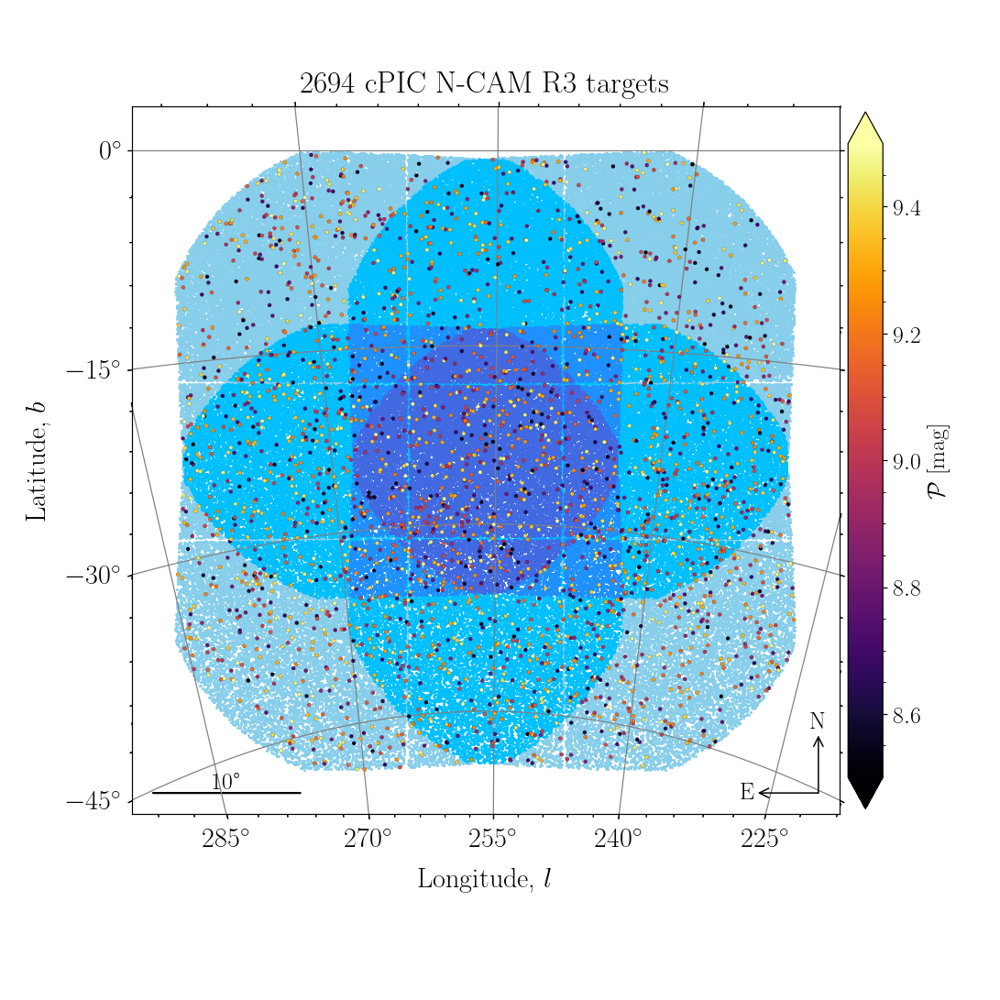

In [49]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 128 == 128]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R3 targets'
)

Plot cPIC `N-CAM R4` sample:

<IPython.core.display.Javascript object>


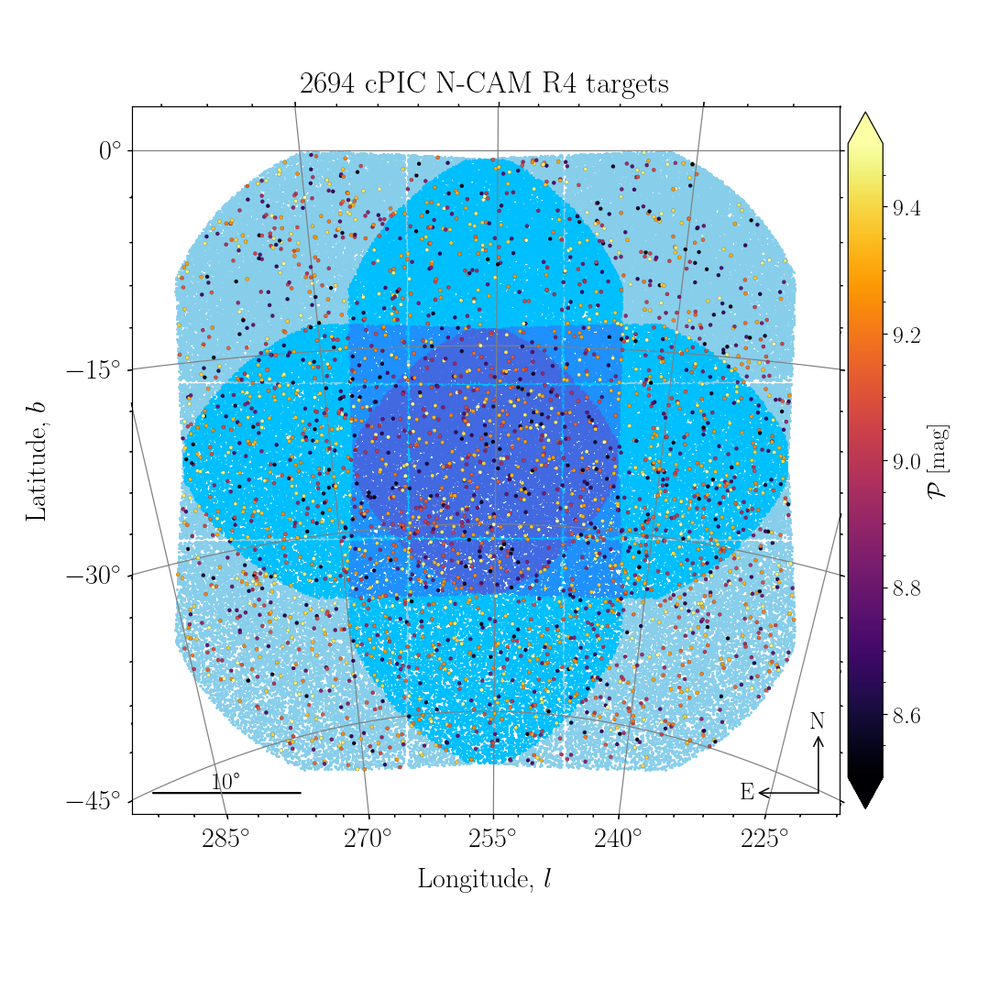

In [50]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 256 == 256]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R4 targets'
)

Plot cPIC `N-CAM R5` sample:

<IPython.core.display.Javascript object>


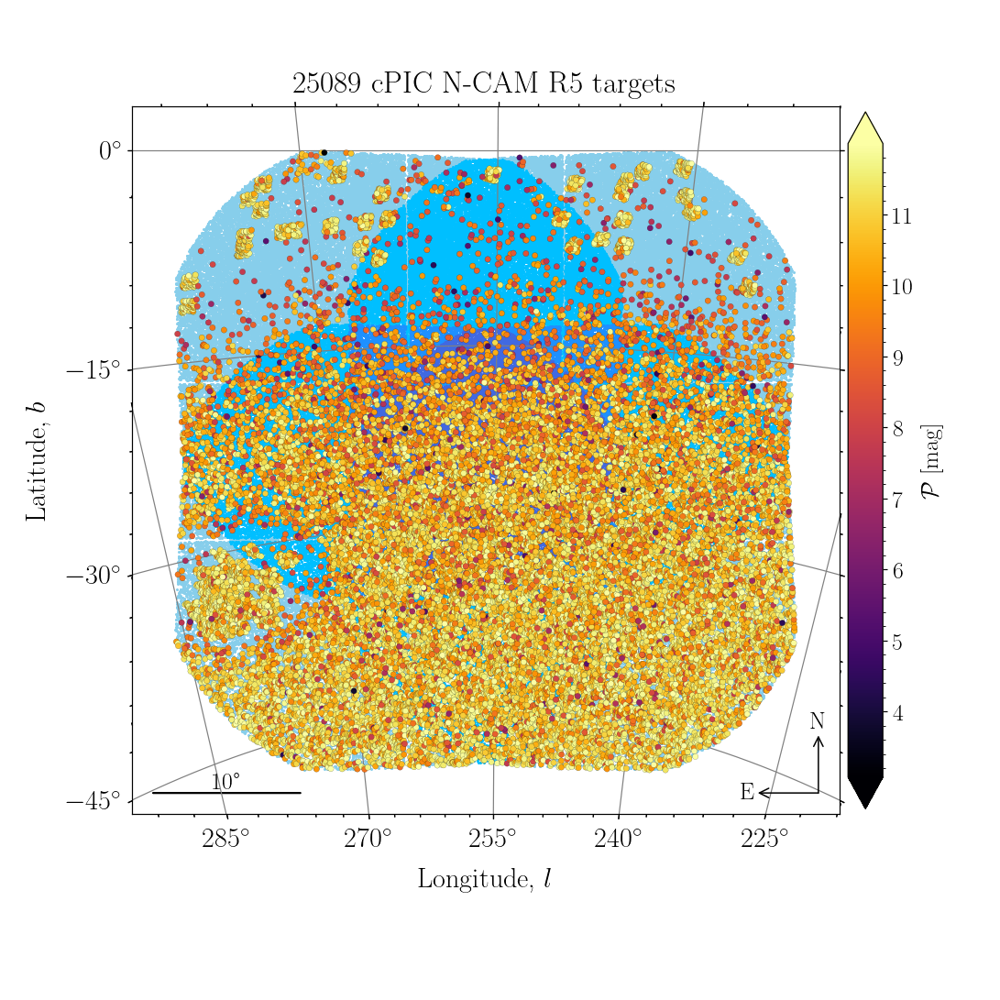

In [51]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 512 == 512]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R5 targets'
)

---
### Plots for scvPIC

Plot `scvPIC` targets:

<IPython.core.display.Javascript object>


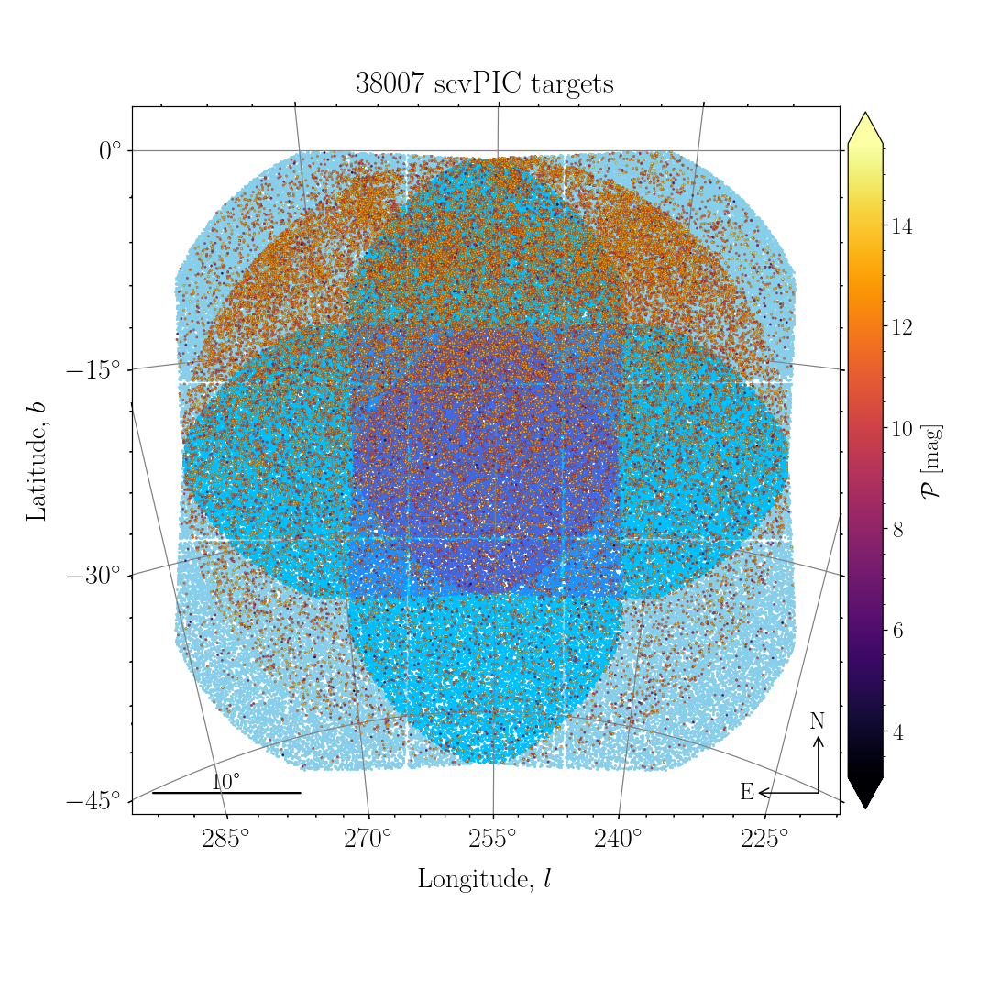

In [52]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['source'] & 32 == 32]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=10, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} scvPIC targets'
)
fig.savefig('skymap_LOPS2_scvPIC2101.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV1a` sample (eclipsing binaries):

<IPython.core.display.Javascript object>


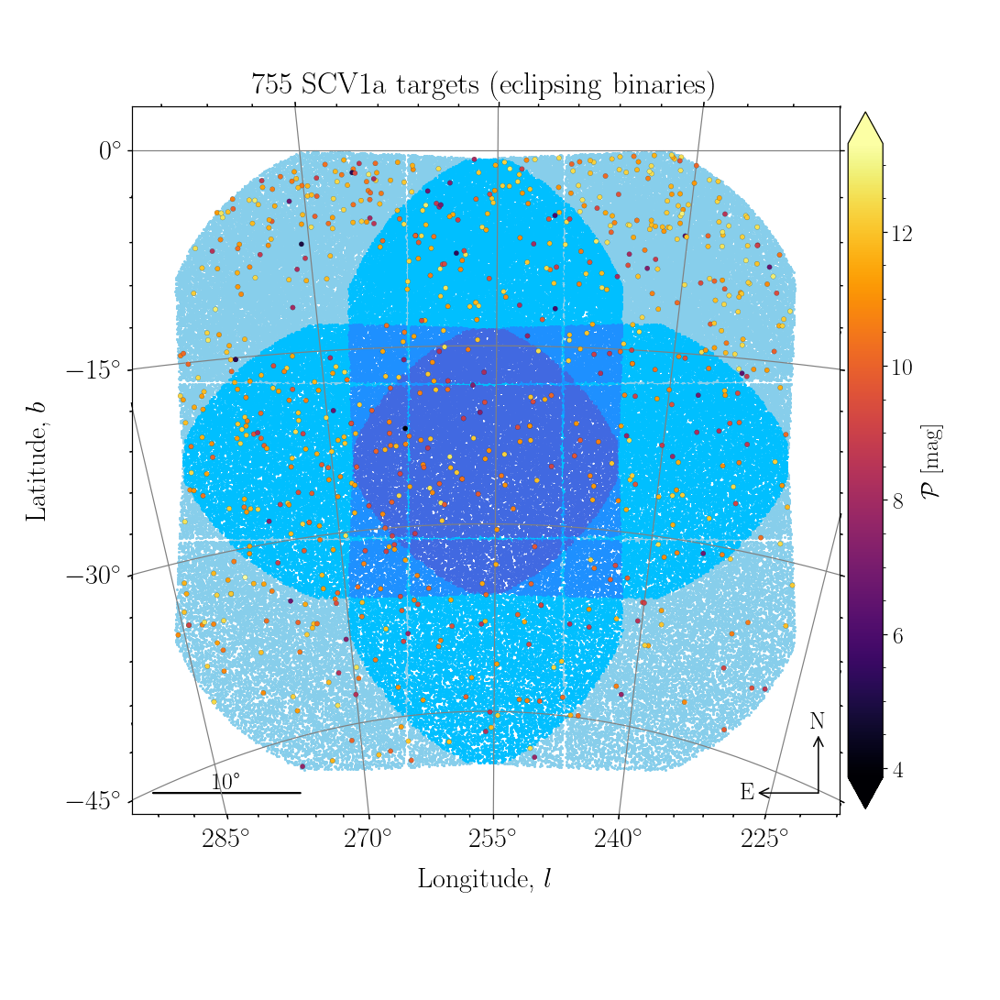

In [53]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 1 == 1]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV1a targets (eclipsing binaries)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV1a.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV1b` sample (astrometric binaries):

<IPython.core.display.Javascript object>


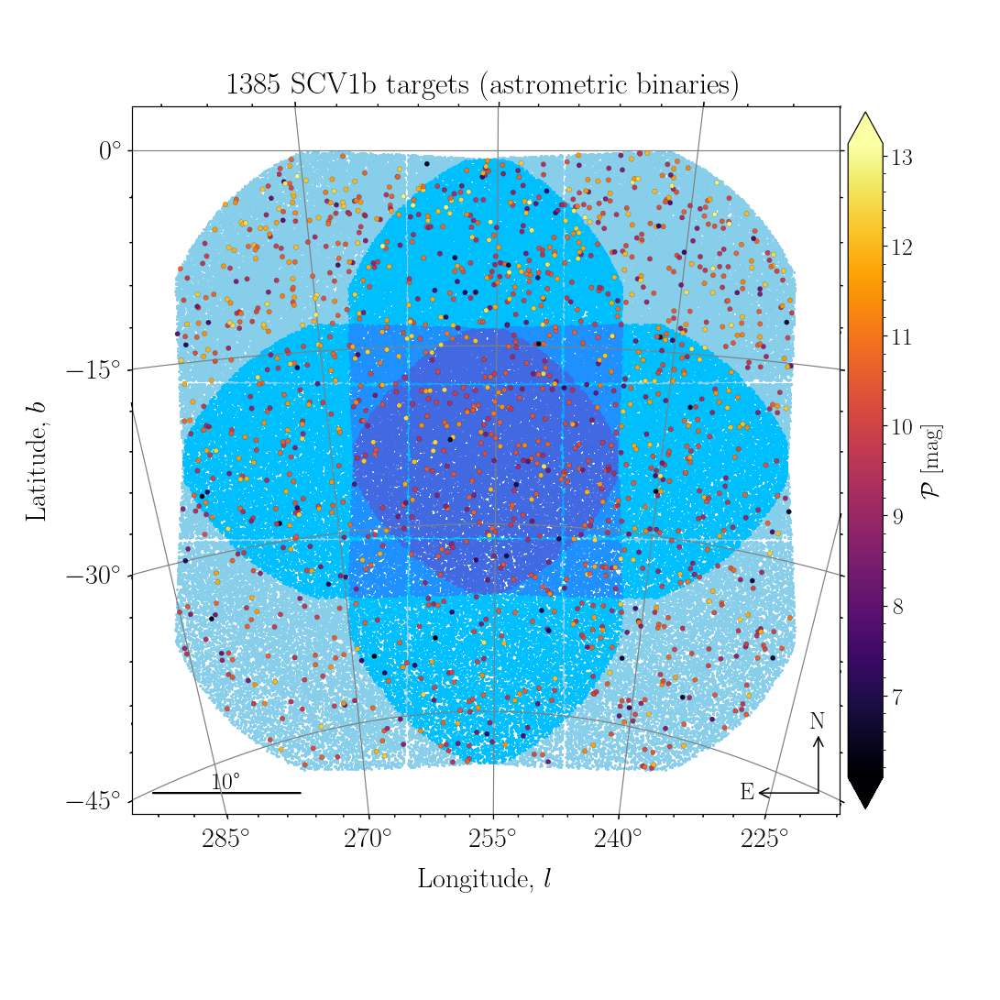

In [54]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 2 == 2]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV1b targets (astrometric binaries)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV1b.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV1c` sample (wide binaries):

<IPython.core.display.Javascript object>


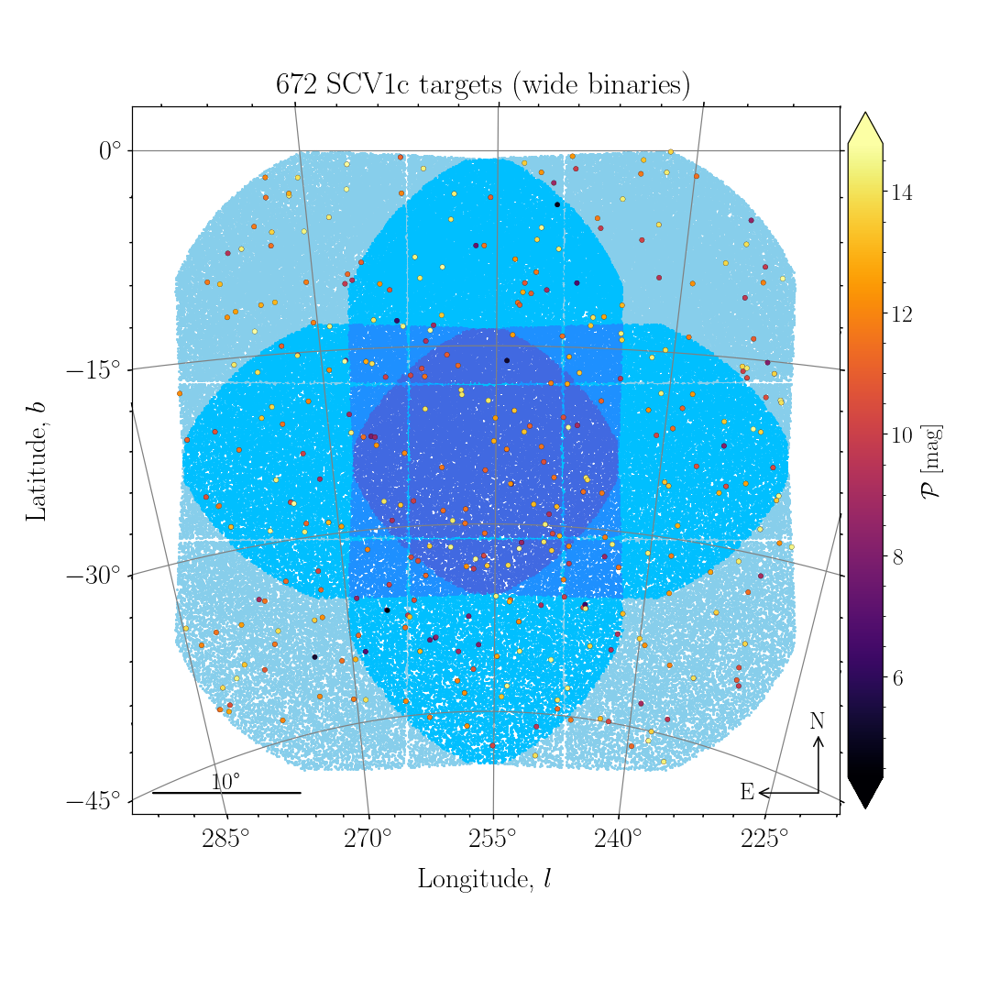

In [55]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 4 == 4]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV1c targets (wide binaries)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV1c.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV1d` sample (HW Vir-type binaries):

<IPython.core.display.Javascript object>


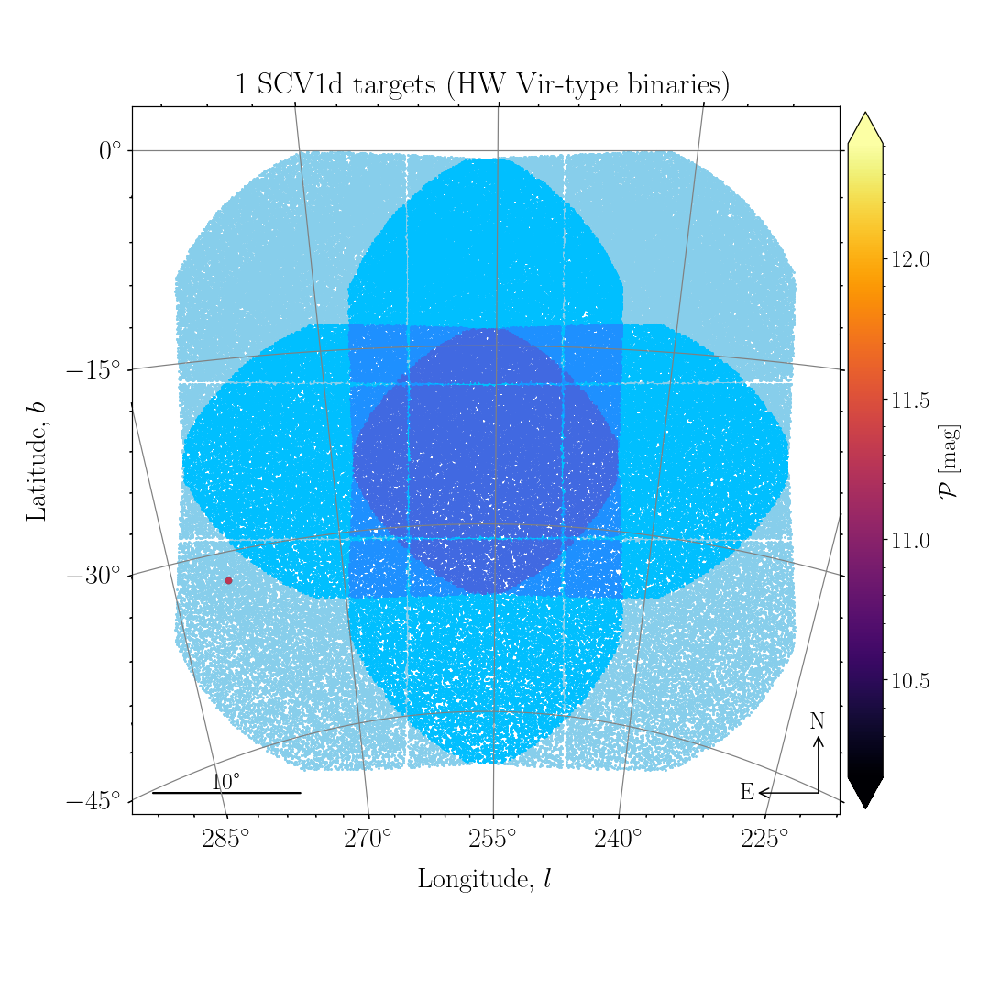

In [56]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 8 == 8]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV1d targets (HW Vir-type binaries)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV1d.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV1e` sample (wide WD binaries):

<IPython.core.display.Javascript object>


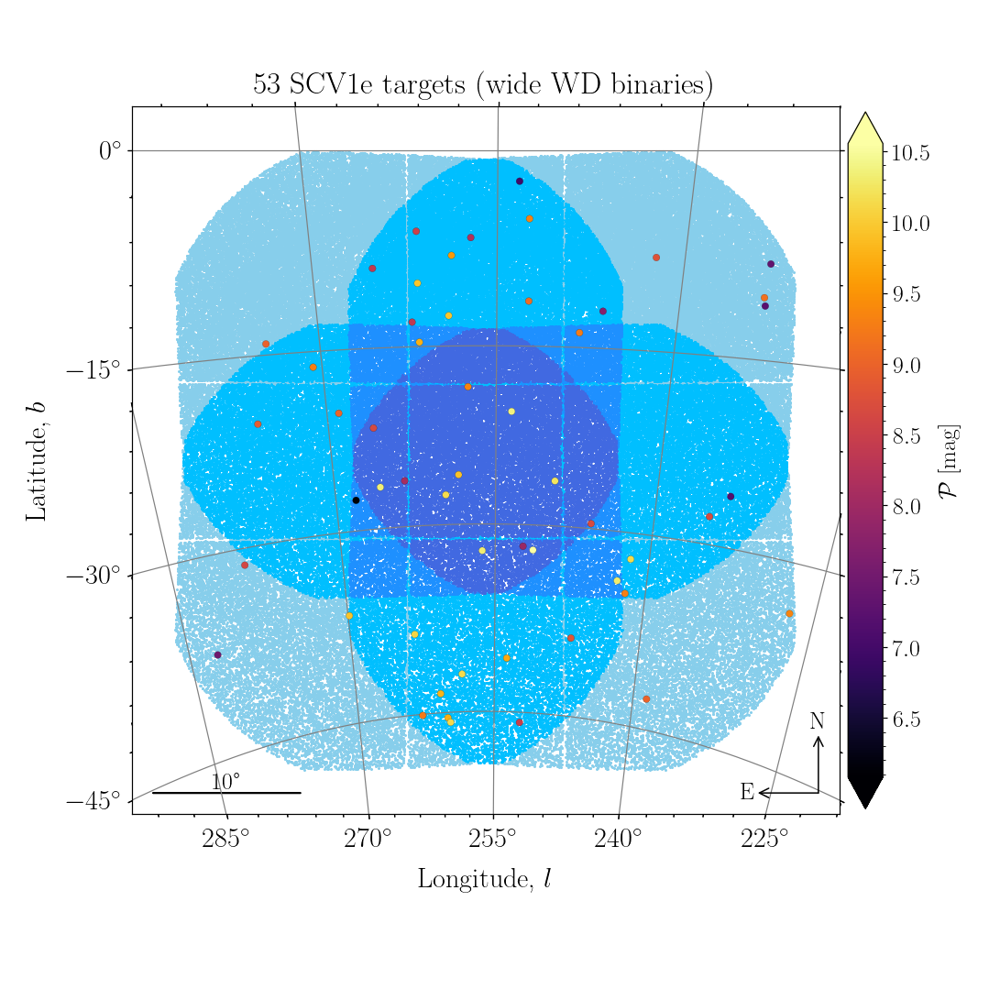

In [57]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 16 == 16]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV1e targets (wide WD binaries)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV1e.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV2a` sample (legacy and benchmark):

<IPython.core.display.Javascript object>


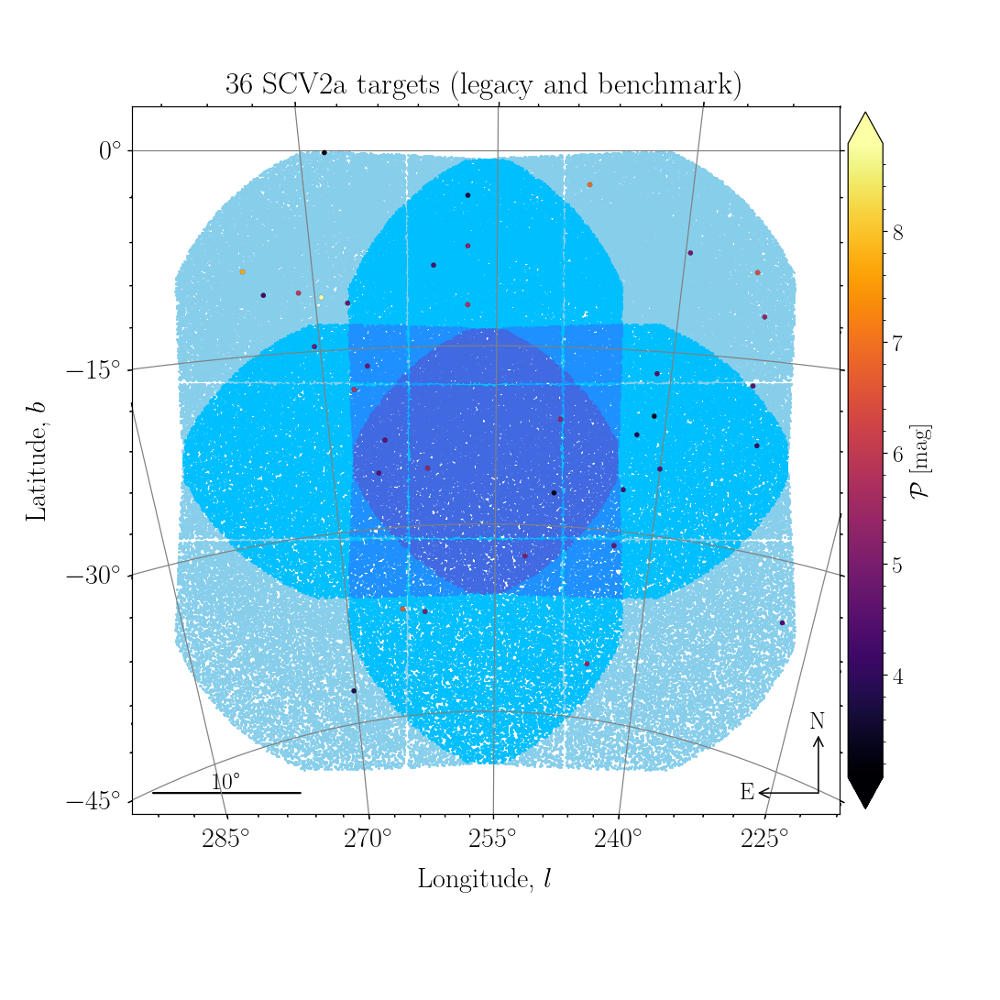

In [58]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 32 == 32]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV2a targets (legacy and benchmark)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV2a.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV2b` sample (legacy and benchmark):

<IPython.core.display.Javascript object>


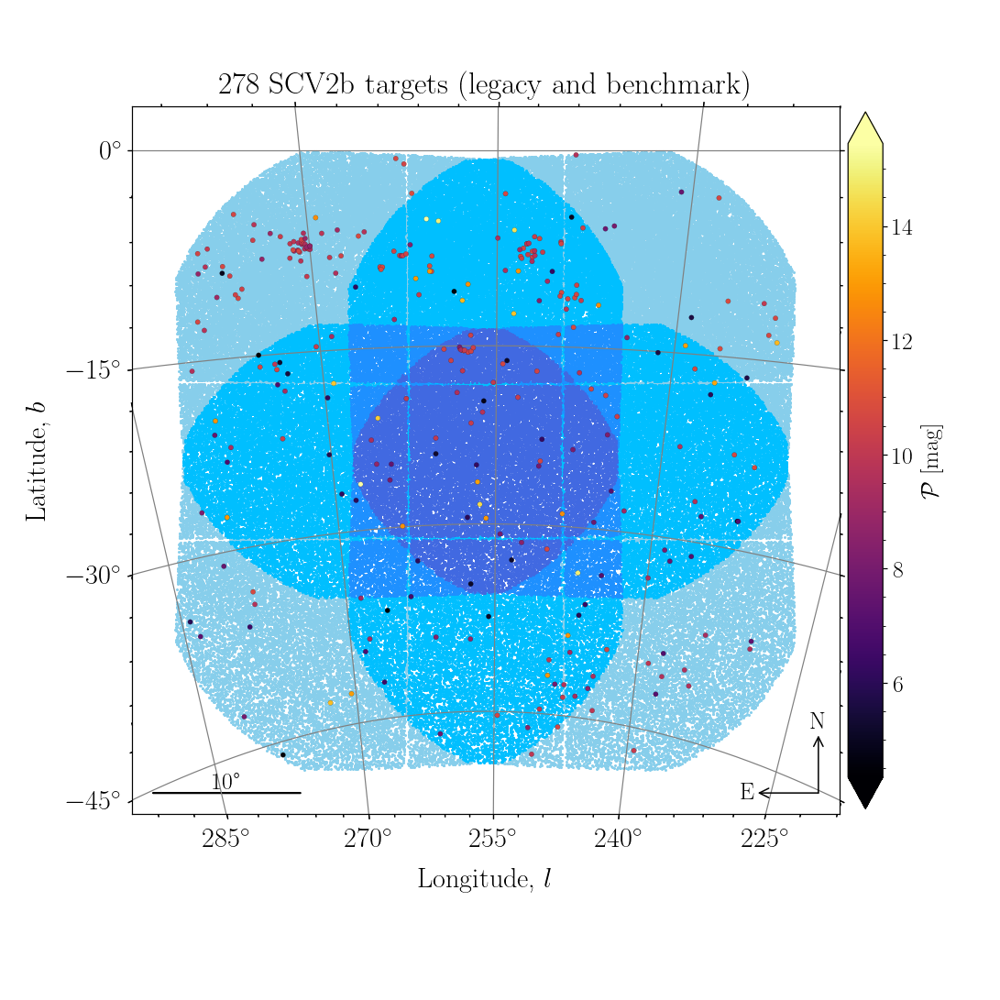

In [59]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 64 == 64]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV2b targets (legacy and benchmark)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV2b.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV3a` sample (photometric stable):

<IPython.core.display.Javascript object>


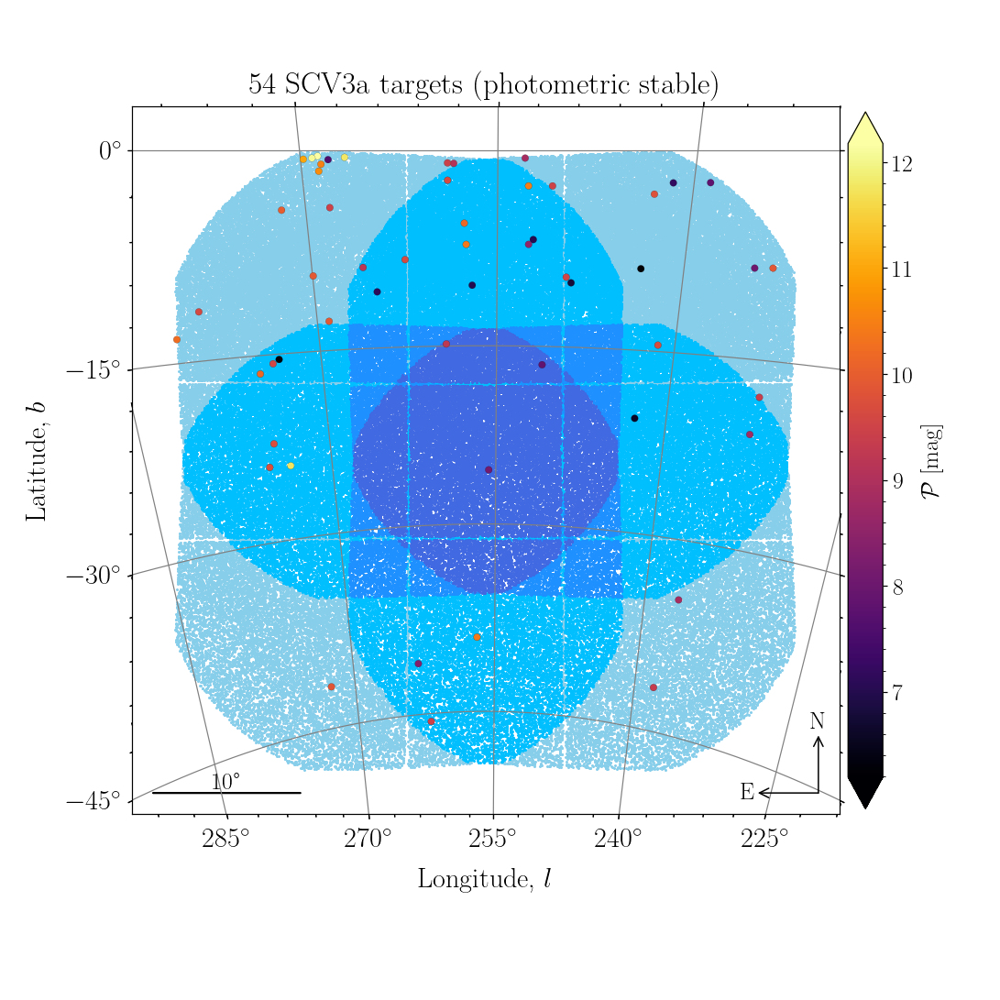

In [60]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 128 == 128]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV3a targets (photometric stable)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV3a.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV3b` sample (photometric stable):

<IPython.core.display.Javascript object>


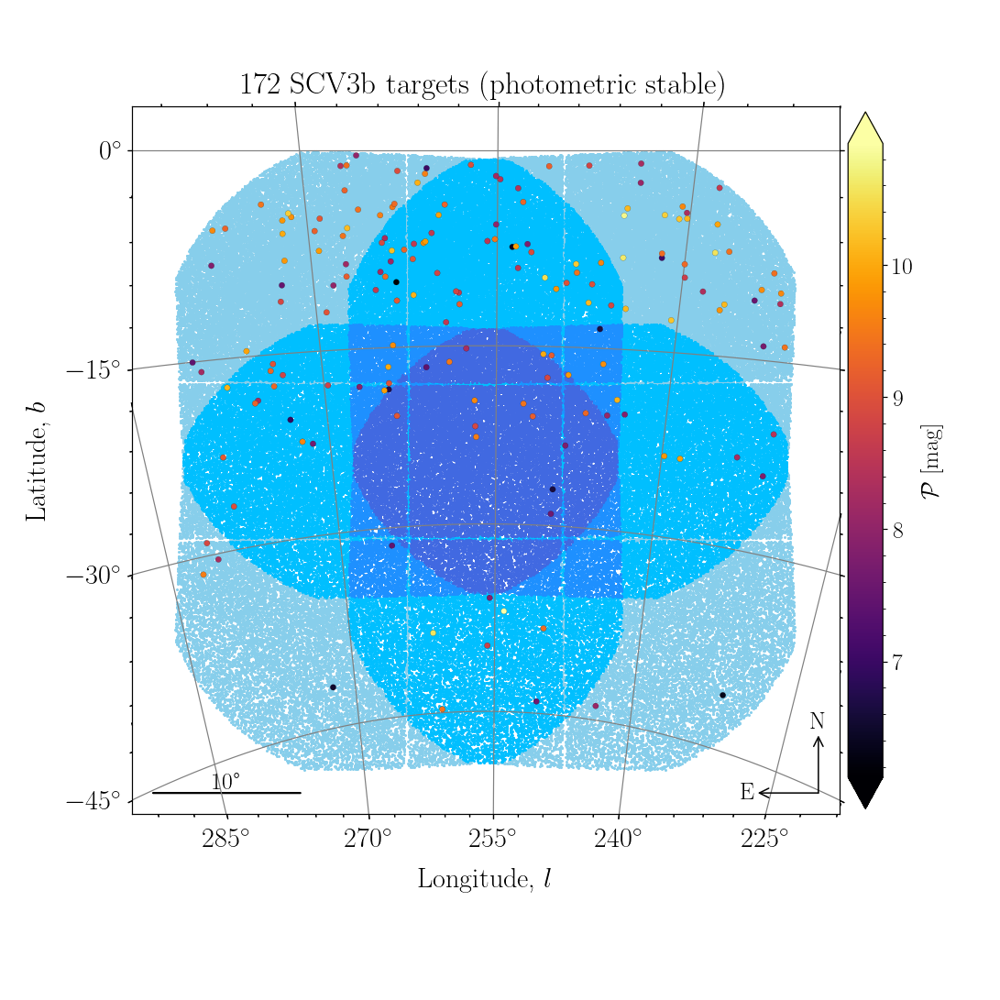

In [61]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 256 == 256]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV3b targets (photometric stable)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV3b.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV4a` sample (solar-like pulsators):

<IPython.core.display.Javascript object>


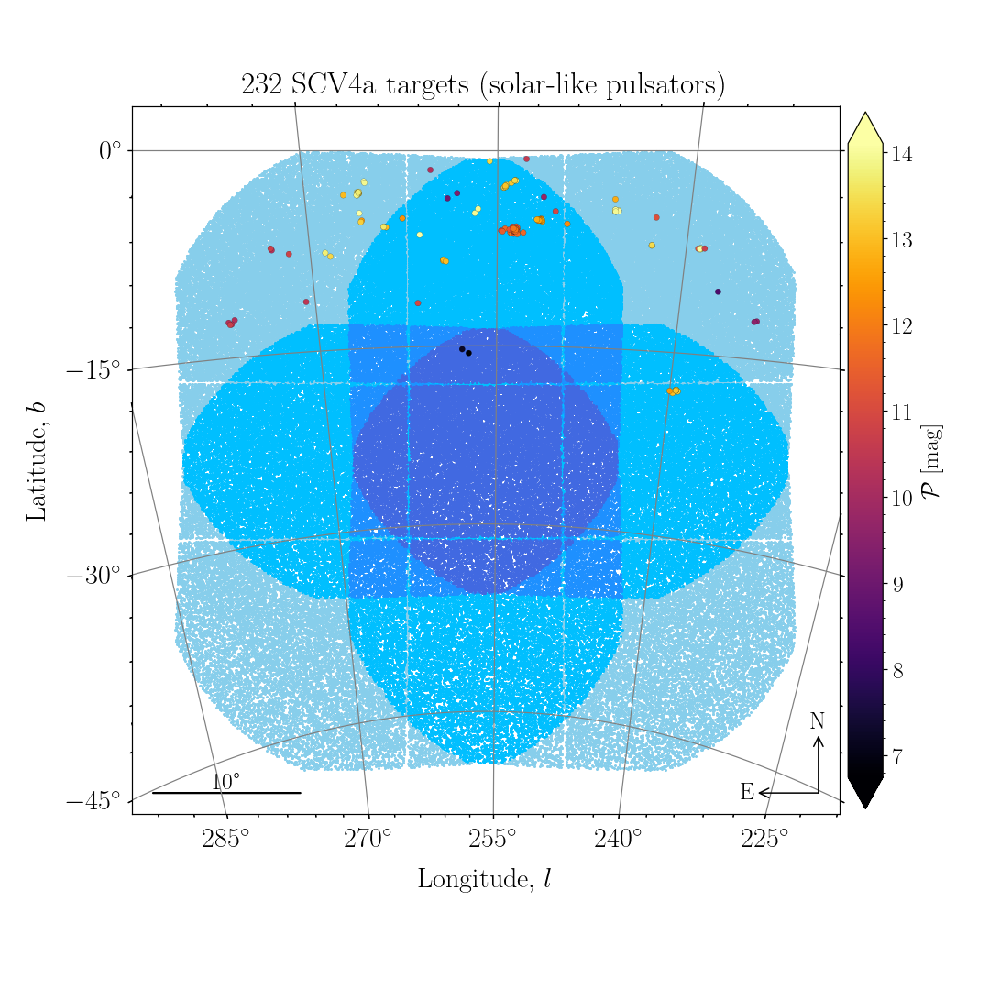

In [62]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 512 == 512]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV4a targets (solar-like pulsators)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV4a.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV4b` sample (solar-like pulsators):

<IPython.core.display.Javascript object>


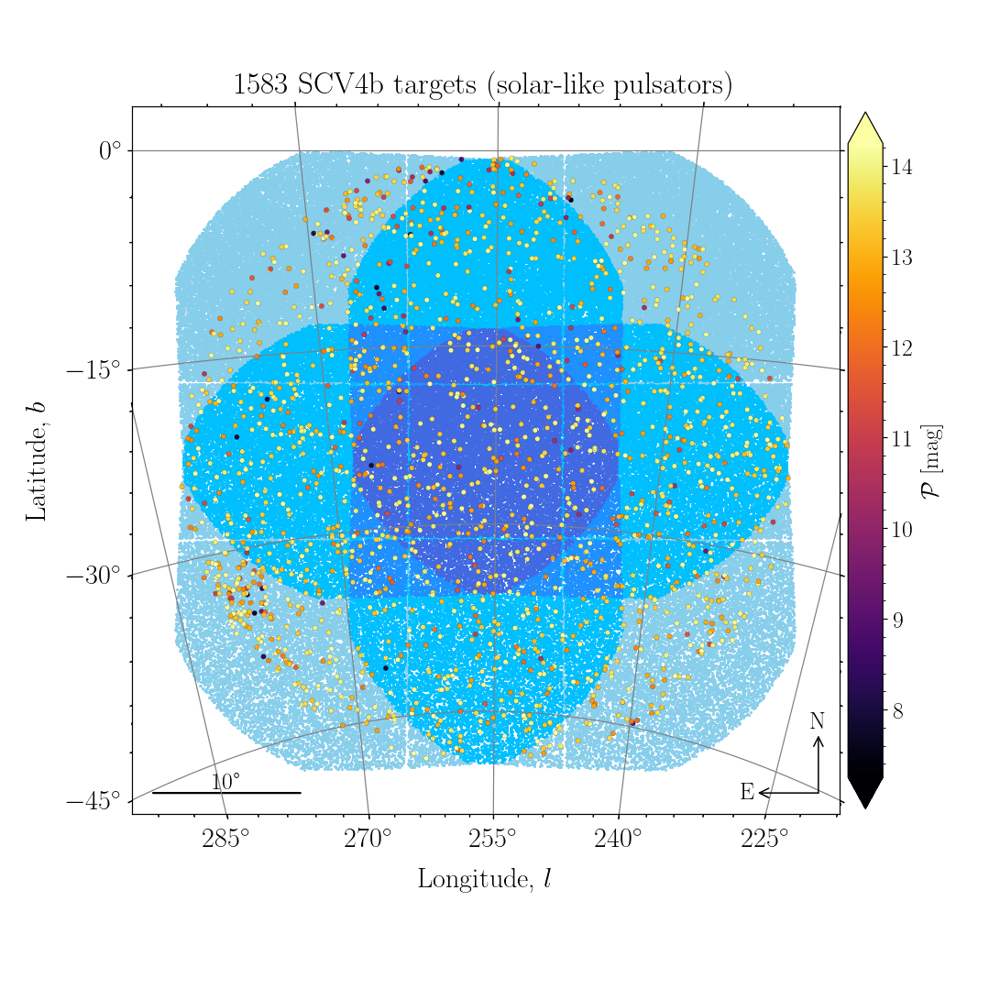

In [68]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 1024 == 1024]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV4b targets (solar-like pulsators)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV4b.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV5` sample (gamma Dor pulsators):

<IPython.core.display.Javascript object>


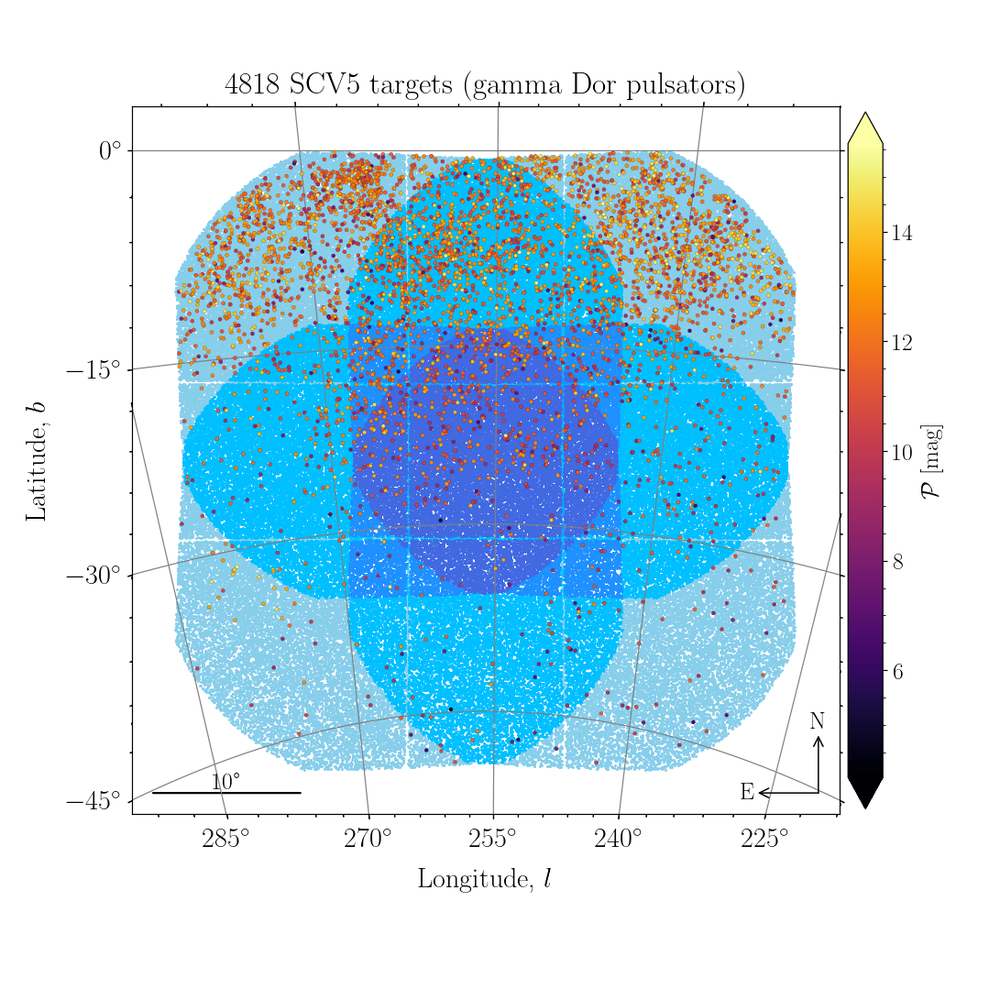

In [64]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 2048 == 2048]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV5 targets (gamma Dor pulsators)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV5.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV6` sample (transiting exoplanets):

<IPython.core.display.Javascript object>


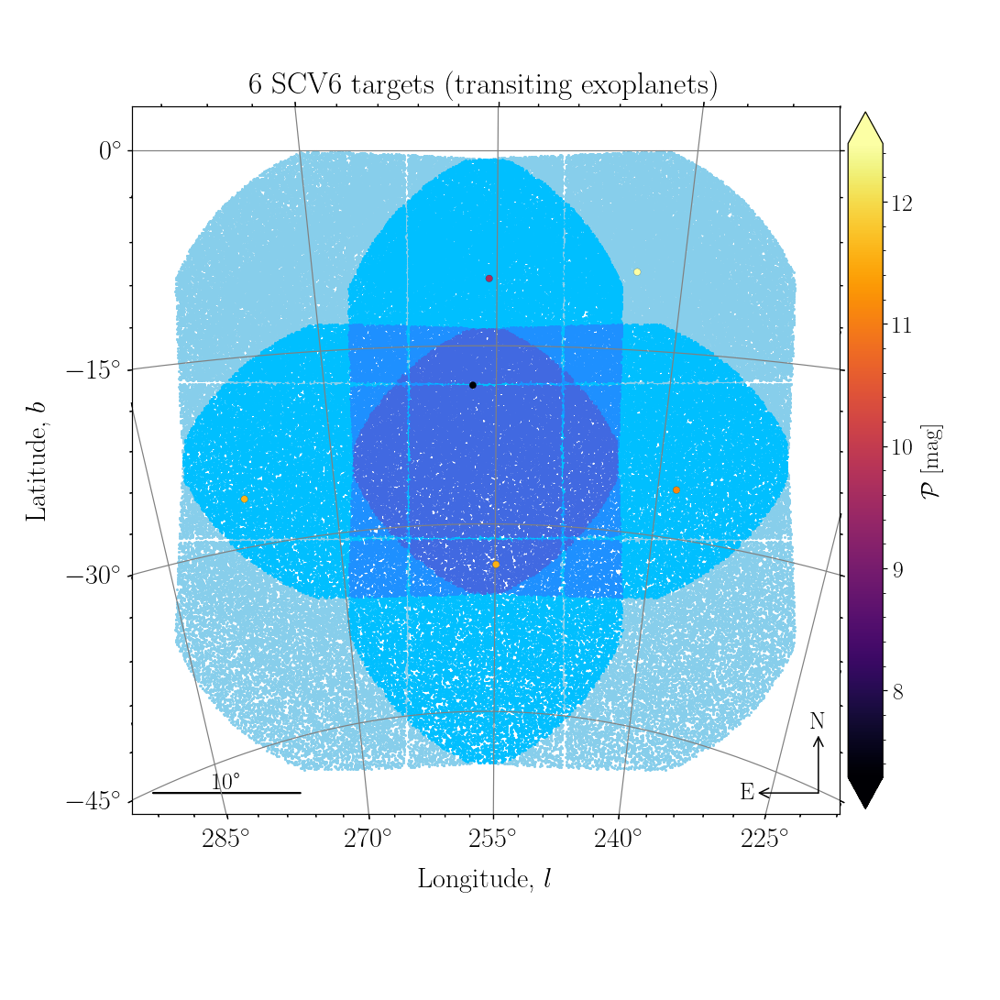

In [65]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 4096 == 4096]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV6 targets (transiting exoplanets)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV6.png', bbox_inches='tight', dpi=200)